# Counterfeit watch CNN: Chapter 4 comparison of the three architectures

Combines the results of `counterfeit_watch_cnn_methodology_v3` for ResNet50, EfficientNetB0 and MobileNetV2, checks that the three runs are comparable (and **stops if they are not**), and builds the Chapter 4 tables and figures.

**Folder to upload.** One sub-folder per model, each holding the v3 result zip or the extracted `tables/`, `predictions/`, `runs/` and `final_model/` folders. The nesting depth does not matter, zips are unzipped automatically, and the model is read from the file names, not the folder name.

```
my_upload/
  resnet50/          resnet50_thesis_results.zip
  efficientnet_b0/   efficientnet_b0_thesis_results.zip
  mobilenet_v2/      tables/  predictions/  runs/  final_model/
```

**Outputs.** Tables as CSV in `comparison/tables/` and figures as PNG in `comparison/figures/`, named by Chapter 4 section (for example `t4_2_4_cv_comparison.csv`, `f4_4_roc_curves.png`). `comparison/chapter4_index.csv` lists every table and figure with its section. Everything is zipped at the end. The notebook runs on CPU in about a minute.

| Section | Content |
|---|---|
| 0 | Inputs and integrity checks (stops on a failure) |
| 4.2.4 | Comparative CV summary, per-fold AUC |
| 4.3 | Frozen thresholds, spread, and 0.3 / 0.5 / 0.7 results |
| 4.4 | Test set: 15-model and final-model results, confusion matrices, ROC curves |
| 4.5 | Statistical comparison: paired group bootstrap, McNemar, Nadeau-Bengio |
| 4.5.2 | Literature scaffold table |
| 4.5.3 | Error patterns: rates, missed images, sellers, hardest images |
| 4.6 | Complexity, accuracy-efficiency plots, training time, Pareto frontier |

In [1]:
# ==============================================================================
# SECTION 0A: SETUP AND CONFIGURATION  (the only cell you normally edit)
# ==============================================================================
import os, re, glob, json, zipfile, hashlib, warnings, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.stats import rankdata, binomtest
from sklearn.metrics import roc_curve
from tqdm.auto import tqdm
try:
    from IPython.display import display
except Exception:
    display = lambda x: print(x.to_string() if hasattr(x, "to_string") else x)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

COMPARE_ROOT = None      # folder that holds the model folders. None = search everything under /kaggle/input
ARCH_ORDER   = ["resnet50", "efficientnet_b0", "mobilenet_v2"]   # the three architectures, in display order
N_FOLDS, N_SEEDS = 5, 3
EXPECTED_RUNS = N_FOLDS * N_SEEDS        # 15 runs per architecture
STRICT       = True      # True = stop with an error when any integrity check fails
READ_FINAL_MODEL_META = True   # open each final .pth on CPU and compare its preprocessing metadata (needs torch; loads your own files with pickle)
N_BOOT       = 2000      # group bootstrap resamples
BOOT_SEED    = 7
ALPHA        = 0.05
FIXED_THRESHOLDS = [0.3, 0.5, 0.7]
RUN_NB_TTEST = True      # optional Nadeau-Bengio corrected t-test on the 15 paired held-out AUCs
PARETO_EVAL    = "test"      # Pareto section: "test" = external test, "heldout" = cross-validation
PARETO_QUALITY = "roc_auc"   # Pareto section: "roc_auc" (primary metric) or "accuracy"

DISPLAY = {"resnet50": "ResNet50", "efficientnet_b0": "EfficientNetB0", "mobilenet_v2": "MobileNetV2"}
COLORS  = {"resnet50": "#4C72B0", "efficientnet_b0": "#DD8452", "mobilenet_v2": "#55A868"}
M5 = ["accuracy", "precision", "recall", "f1", "roc_auc"]
MLAB = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1", "roc_auc": "ROC-AUC"}
def dn(a): return DISPLAY.get(a, a)
def col(a): return COLORS.get(a, "grey")

KAGGLE     = os.path.exists("/kaggle")
INPUT_ROOT = COMPARE_ROOT or ("/kaggle/input" if KAGGLE else "./input")
WORK       = "/kaggle/working" if KAGGLE else "./working"
OUT        = f"{WORK}/comparison"
FIG, TAB   = f"{OUT}/figures", f"{OUT}/tables"
for d in (FIG, TAB): os.makedirs(d, exist_ok=True)

INDEX = []   # every table and figure written, with its Chapter 4 section
def savetab(df, name, section, desc, index=False):
    df.to_csv(f"{TAB}/{name}", index=index); INDEX.append(dict(type="table", section=section, file=f"tables/{name}", description=desc))
def savefig(name, section, desc):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}", dpi=200, bbox_inches="tight"); INDEX.append(dict(type="figure", section=section, file=f"figures/{name}", description=desc)); plt.show()

print("input root:", INPUT_ROOT, "| output:", OUT)

input root: /kaggle/input | output: /kaggle/working/comparison


In [2]:
# ==============================================================================
# SECTION 0B: FIND THE MODEL RESULT FOLDERS (unzips result zips automatically)
# ==============================================================================
def is_output_dir(d):
    return os.path.isdir(f"{d}/predictions") and os.path.isdir(f"{d}/tables") and bool(glob.glob(f"{d}/predictions/oof_predictions_*.csv"))

def find_output_dirs(root):
    found = []
    for cur, dirs, _ in os.walk(root):
        if is_output_dir(cur): found.append(cur); dirs[:] = []
    return found

out_dirs = find_output_dirs(INPUT_ROOT)
for cur, _, files in os.walk(INPUT_ROOT):
    for f in files:
        if f.endswith(".zip") and not any(o.startswith(cur + os.sep) for o in out_dirs):
            with zipfile.ZipFile(f"{cur}/{f}") as z:
                keep = [n for n in z.namelist() if n.split("/")[0] in ("tables", "predictions", "runs", "final_model")]
                if not any(n.startswith("predictions/") for n in keep): continue
                dest = f"{WORK}/unzipped/{os.path.basename(cur)}_{f[:-4]}"; z.extractall(dest, members=keep)
            out_dirs += find_output_dirs(dest); print("[*] unzipped", f"{cur}/{f}")
assert out_dirs, f"No v3 result folder (predictions/ + tables/) or result zip found under {INPUT_ROOT}. Set COMPARE_ROOT to the uploaded folder."

MODELS = {}
for od in out_dirs:
    for f in glob.glob(f"{od}/predictions/oof_predictions_*.csv"):
        arch = re.search(r"oof_predictions_(.+)\.csv$", os.path.basename(f)).group(1)
        if arch in MODELS:
            print(f"[!] {arch} found twice ({MODELS[arch]['dir']} and {od}); keeping the more recent one")
            if os.path.getmtime(f) <= MODELS[arch]["mtime"]: continue
        MODELS[arch] = dict(dir=od, mtime=os.path.getmtime(f))
ARCHS = [a for a in ARCH_ORDER if a in MODELS] + sorted(a for a in MODELS if a not in ARCH_ORDER)
for a in ARCHS: print(f"  {dn(a):16s} {MODELS[a]['dir']}")

  ResNet50         /kaggle/input/datasets/angelaysabelle/final-outputs-cnn/outputs/resnet50
  EfficientNetB0   /kaggle/input/datasets/angelaysabelle/final-outputs-cnn/outputs/efficientnet_b0
  MobileNetV2      /kaggle/input/datasets/angelaysabelle/final-outputs-cnn/outputs/mobilenet_v2


## 0. Inputs and integrity checks
Reads `tables/`, `predictions/`, `runs/` and `final_model/` of each architecture and checks that the three are comparable. A FAIL stops the notebook (`STRICT = True`). The settings are verified through the `config_sig` stored in every run, a hash of the epochs, unfrozen blocks, learning rates, weight decay, label smoothing, BatchNorm freezing, augmentation strength, dropout, batch size, input size and the fold file.

In [3]:
# ==============================================================================
# SECTION 0C: LOAD EVERYTHING AND CHECK INTEGRITY (stops on a failure)
# ==============================================================================
# CHAPTER 3: Data Partitioning (shared folds, seeds, settings), Evaluation (15 runs and one final model per architecture)
def rd(p):
    try: return pd.read_csv(p) if os.path.exists(p) else None
    except Exception: return None
def md5(p): return hashlib.md5(open(p, "rb").read()).hexdigest()[:12]
def D(a): return MODELS[a]["dir"]

RUNS, OOF, TST, FIN, FINROW, CX, CXL, AUDIT, RUNJSON, RUNPRED = {}, {}, {}, {}, {}, {}, {}, {}, {}, {}
def clean(df):
    if df is None: return None
    df = df.copy(); df["image_id"] = df["image_id"].astype(str)
    df["group_id"] = (df["group_id"] if "group_id" in df.columns else df["image_id"]).where(lambda s: s.notna(), df["image_id"]).astype(str)
    if "seller" in df.columns: df["seller"] = df["seller"].where(df["seller"].notna(), "unknown").astype(str)
    if "brand_website" in df.columns: df["brand_website"] = df["brand_website"].astype(str).str.lower().isin(["true", "1", "1.0"])
    return df
for a in ARCHS:
    RUNS[a] = rd(f"{D(a)}/tables/runs_{a}.csv"); OOF[a] = clean(rd(f"{D(a)}/predictions/oof_predictions_{a}.csv")); TST[a] = clean(rd(f"{D(a)}/predictions/test_predictions_{a}.csv"))
    FIN[a] = clean(rd(f"{D(a)}/predictions/final_model_test_predictions_{a}.csv")); FINROW[a] = rd(f"{D(a)}/tables/table_final_model_{a}.csv")
    CX[a] = rd(f"{D(a)}/tables/complexity_{a}.csv"); CXL[a] = rd(f"{D(a)}/tables/complexity_layers_{a}.csv"); AUDIT[a] = rd(f"{D(a)}/tables/table_shortcut_audit.csv")
    RUNJSON[a] = [json.load(open(f)) for f in sorted(glob.glob(f"{D(a)}/runs/**/{a}_f*_s*.json", recursive=True))]    # flat runs/ or the older runs/<arch>/ layout
    RUNPRED[a] = sorted(glob.glob(f"{D(a)}/runs/**/{a}_f*_s*_preds.csv", recursive=True))
FOLDF = {a: rd(f"{D(a)}/tables/fold_assignments.csv") for a in ARCHS}
FILES = lambda a: dict(runs_table=f"{D(a)}/tables/runs_{a}.csv", oof=f"{D(a)}/predictions/oof_predictions_{a}.csv", test=f"{D(a)}/predictions/test_predictions_{a}.csv",
                       final_pred=f"{D(a)}/predictions/final_model_test_predictions_{a}.csv", final_table=f"{D(a)}/tables/table_final_model_{a}.csv", complexity=f"{D(a)}/tables/complexity_{a}.csv",
                       fold_file=f"{D(a)}/tables/fold_assignments.csv", final_pth=f"{D(a)}/final_model/{a}_final.pth", final_pt=f"{D(a)}/final_model/{a}_final.pt")

CHK = []
def check(name, ok, detail, level="FAIL"): CHK.append(dict(check=name, status="OK" if ok else level, detail=detail))
def per_arch(name, fn, level="FAIL"):
    res = {a: fn(a) for a in ARCHS}; bad = {a: t for a, (ok, t) in res.items() if not ok}
    check(name, not bad, "; ".join(f"{dn(a)}: {t}" for a, t in (bad or {a: r[1] for a, r in res.items()}).items()), level)
def same_across(name, vals, level="FAIL", fmt=str):
    ok = len({repr(v) for v in vals.values()}) == 1
    check(name, ok, fmt(next(iter(vals.values()))) if ok else "; ".join(f"{dn(a)}: {fmt(v)}" for a, v in vals.items()), level)

# ---- presence --------------------------------------------------------------------------------------------------------
check("The three expected architectures are present", all(a in MODELS for a in ARCH_ORDER) and len(ARCHS) == len(ARCH_ORDER), ", ".join(dn(a) for a in ARCHS) if ARCHS else "none found")
def f_files(a):
    miss = [k for k, p in FILES(a).items() if not os.path.exists(p)]; return not miss, "all found" if not miss else "missing " + ", ".join(miss)
per_arch("Required files exist: tables, predictions, final-model predictions and table, final .pth and .pt", f_files)
per_arch("runs/ folder exists", lambda a: (os.path.isdir(f"{D(a)}/runs"), "found" if os.path.isdir(f"{D(a)}/runs") else "missing"))
def f_size(a):
    bad = [k for k in ("final_pth", "final_pt") if os.path.exists(FILES(a)[k]) and os.path.getsize(FILES(a)[k]) == 0]; return not bad, "non-empty" if not bad else "empty " + ", ".join(bad)
per_arch("Final-model files are not empty", f_size)

# ---- 15 runs and one final model per architecture -----------------------------------------------------------------------
def f_runs(a):
    r = RUNS[a]
    if r is None: return False, "runs table missing"
    keys = set(zip(r.fold, r.seed)); ok = len(r) == EXPECTED_RUNS and len(keys) == EXPECTED_RUNS and set(r.fold) == set(range(N_FOLDS)) and r.seed.nunique() == N_SEEDS
    return ok, f"{len(r)} rows, {len(keys)} distinct fold/seed pairs, {r.seed.nunique()} seeds"
per_arch(f"{EXPECTED_RUNS} runs in runs_<arch>.csv ({N_FOLDS} folds x {N_SEEDS} seeds)", f_runs)
def f_runfiles(a):
    n_h = len(glob.glob(f"{D(a)}/runs/**/{a}_f*_s*_history.csv", recursive=True)); ok = len(RUNJSON[a]) == len(RUNPRED[a]) == n_h == EXPECTED_RUNS
    return ok, f"{len(RUNJSON[a])} json, {len(RUNPRED[a])} predictions, {n_h} histories"
per_arch(f"runs/ holds {EXPECTED_RUNS} run files of each kind", f_runfiles)
def f_runpreds(a):
    if OOF[a] is None or TST[a] is None or not RUNPRED[a]: return False, "files missing"
    tot = sum(len(pd.read_csv(f)) for f in RUNPRED[a]); exp = len(OOF[a]) + len(TST[a]); ids = {os.path.basename(f)[:-10] for f in RUNPRED[a]}
    ok = tot == exp and ids == set(OOF[a].run_id) == set(TST[a].run_id); return ok, f"{tot} rows in runs/ vs {exp} in predictions/"
per_arch("runs/ predictions agree with predictions/oof and test files", f_runpreds)
def f_final(a):
    if FINROW[a] is None or FIN[a] is None or TST[a] is None: return False, "files missing"
    ok = len(FINROW[a]) == 1 and set(FIN[a].image_id) == set(TST[a].image_id) and FIN[a].image_id.is_unique; return ok, f"{len(FINROW[a])} final model, {FIN[a].image_id.nunique()} test predictions"
per_arch("Exactly one final model, scored on every test image once", f_final)

# ---- same settings ---------------------------------------------------------------------------------------------------
def f_sig(a):
    if RUNS[a] is None or "config_sig" not in RUNS[a]: return False, "config_sig missing"
    s_csv, s_json = set(RUNS[a].config_sig.astype(str)), {str(j.get("config_sig")) for j in RUNJSON[a]}
    return len(s_csv) == 1 and s_csv == s_json, f"{next(iter(s_csv))}" if len(s_csv) == 1 and s_csv == s_json else f"table {sorted(s_csv)}, json {sorted(s_json)}"
per_arch("One settings hash (config_sig) in every run of the architecture, table and run files agree", f_sig)
if all(RUNS[a] is not None and "config_sig" in RUNS[a] for a in ARCHS):
    same_across("Same settings hash in all three architectures (epochs, unfrozen blocks, learning rates, augmentation, ...)", {a: RUNS[a].config_sig.astype(str).iloc[0] for a in ARCHS})
for c in ["input_size"]:
    if all(RUNS[a] is not None for a in ARCHS): same_across(f"Same {c}", {a: sorted(RUNS[a][c].unique().tolist()) for a in ARCHS})
if all(RUNS[a] is not None for a in ARCHS):
    sizes = {a: RUNS[a].sort_values(["seed", "fold"])[["n_train", "n_val", "n_heldout"]].values.tolist() for a in ARCHS}
    same_across("Same training, validation and held-out sizes in every run", {a: hashlib.md5(repr(v).encode()).hexdigest()[:8] for a, v in sizes.items()})
if all(FINROW[a] is not None for a in ARCHS):
    for c in ["mode", "trained_on_images", "phase1_epochs"]:
        if all(c in FINROW[a] for a in ARCHS): same_across(f"Final models: same {c}", {a: FINROW[a][c].iloc[0] for a in ARCHS})

# ---- same folds, pool images and test images --------------------------------------------------------------------------
if all(FOLDF[a] is not None for a in ARCHS):
    h = {a: md5(FILES(a)["fold_file"]) for a in ARCHS}
    if len(set(h.values())) == 1: check("fold_assignments.csv identical in all three (file hash)", True, h[ARCHS[0]])
    else:
        ref = FOLDF[ARCHS[0]].sort_values("image_id").reset_index(drop=True)
        cont = all(FOLDF[a].sort_values("image_id").reset_index(drop=True).equals(ref) for a in ARCHS[1:])
        check("fold_assignments.csv identical in all three (file hash)", cont, ("hashes differ but the content is identical: " if cont else "different folds: ") + str(h))
    def f_foldused(a):
        o = OOF[a].drop_duplicates(["image_id", "seed"]); m = o.merge(FOLDF[a][["image_id", "fold"]].assign(image_id=lambda d: d.image_id.astype(str)), on="image_id", suffixes=("", "_file"))
        return len(m) == len(o) and bool((m.fold == m.fold_file).all()), "predictions use the folds of the file" if len(m) == len(o) and bool((m.fold == m.fold_file).all()) else "fold of some images differs from the fold file"
    per_arch("Folds used in the out-of-fold predictions match fold_assignments.csv", f_foldused)
    same_across("Same pool image_id list (fold file)", {a: hashlib.md5(",".join(sorted(FOLDF[a].image_id.astype(str))).encode()).hexdigest()[:8] for a in ARCHS})
if all(OOF[a] is not None for a in ARCHS):
    same_across("Same pool image_id list (out-of-fold predictions)", {a: hashlib.md5(",".join(sorted(set(OOF[a].image_id))).encode()).hexdigest()[:8] for a in ARCHS}, fmt=lambda v: f"{v}")
    per_arch("Every pool image is held out exactly once per seed", lambda a: (bool((OOF[a].groupby(["seed", "image_id"]).size() == 1).all()) and OOF[a].seed.nunique() == N_SEEDS, "yes" if bool((OOF[a].groupby(["seed", "image_id"]).size() == 1).all()) else "duplicates"))
if all(TST[a] is not None and FIN[a] is not None for a in ARCHS):
    same_across("Same test image_id list (15-model predictions and final models)", {a: hashlib.md5(",".join(sorted(set(TST[a].image_id) | set(FIN[a].image_id))).encode()).hexdigest()[:8] for a in ARCHS})
    pool, test = set(OOF[ARCHS[0]].image_id), set(TST[ARCHS[0]].image_id)
    check("Pool and test image lists do not overlap", not (pool & test), f"{len(pool)} pool, {len(test)} test, {len(pool & test)} shared")
    lab = {a: hashlib.md5(repr(sorted(zip(OOF[a].image_id, OOF[a].label))).encode()).hexdigest()[:8] for a in ARCHS}
    same_across("Same labels for every image", lab)

# ---- final-model metadata (optional) ------------------------------------------------------------------------------------
if READ_FINAL_MODEL_META:
    try:
        import torch
        meta = {}
        for a in ARCHS:
            ck = torch.load(FILES(a)["final_pth"], map_location="cpu", weights_only=False)
            meta[a] = {k: (str(v) if not isinstance(v, (int, float, str, list, tuple)) else v) for k, v in ck.items() if k != "state_dict"}
        keys = ["input_size", "imagenet_mean", "imagenet_std", "bg_fill", "class_to_idx", "positive_class", "preprocessing"]
        same_across("Final .pth files carry the same preprocessing metadata", {a: {k: meta[a].get(k) for k in keys} for a in ARCHS}, level="WARN")
        check("Final .pth architecture matches its file name", all(meta[a].get("arch") == a for a in ARCHS), "yes" if all(meta[a].get("arch") == a for a in ARCHS) else str({a: meta[a].get("arch") for a in ARCHS}), "WARN")
    except Exception as e:
        check("Final .pth metadata comparison", False, f"skipped ({type(e).__name__}: {str(e)[:80]})", "INFO")

# ---- comparability of the benchmark and informational rows -----------------------------------------------------------------
if all(CX[a] is not None and "hardware" in CX[a] for a in ARCHS):
    same_across("Same hardware for the complexity benchmark (latency and training time are only comparable on one GPU)", {a: str(CX[a].hardware.iloc[0]) for a in ARCHS}, level="WARN")
check("Layer tables for the per-layer complexity terms", all(CXL[a] is not None for a in ARCHS), "all found" if all(CXL[a] is not None for a in ARCHS) else "missing for " + ", ".join(dn(a) for a in ARCHS if CXL[a] is None), "WARN")
if all(RUNS[a] is not None and "theta_fallback" in RUNS[a] for a in ARCHS):
    check("Runs whose validation threshold fell back to 0.5", True, ", ".join(f"{dn(a)} {int(RUNS[a].theta_fallback.sum())}" for a in ARCHS), "INFO")

chk = pd.DataFrame(CHK); savetab(chk, "t4_0_integrity_checks.csv", "0", "Inputs and integrity checks")
pd.set_option("display.max_colwidth", 140); display(chk)
n_fail = int((chk.status == "FAIL").sum()); n_warn = int((chk.status == "WARN").sum())
print(f"\n{len(chk)} checks: {int((chk.status == 'OK').sum())} OK, {n_warn} WARN, {n_fail} FAIL")
if n_fail and STRICT:
    print("\nFAILED CHECKS:"); display(chk[chk.status == "FAIL"][["check", "detail"]])
    raise RuntimeError(f"{n_fail} integrity check(s) failed (see the table above). Fix the inputs, or set STRICT = False to continue anyway. Nothing below is valid until they pass.")
if n_warn: print("[!] WARN rows do not stop the notebook, but read them before reporting.")
HAVE_CX = all(CX[a] is not None for a in ARCHS)

,check,status,detail
0,The three expected architectures are present,OK,"ResNet50, EfficientNetB0, MobileNetV2"
1,"Required files exist: tables, predictions, final-model predictions and table, final .pth and .pt",OK,ResNet50: all found; EfficientNetB0: all found; MobileNetV2: all found
2,runs/ folder exists,OK,ResNet50: found; EfficientNetB0: found; MobileNetV2: found
3,Final-model files are not empty,OK,ResNet50: non-empty; EfficientNetB0: non-empty; MobileNetV2: non-empty
4,15 runs in runs_<arch>.csv (5 folds x 3 seeds),OK,"ResNet50: 15 rows, 15 distinct fold/seed pairs, 3 seeds; EfficientNetB0: 15 rows, 15 distinct fold/seed pairs, 3 seeds; MobileNetV2: 15 ..."
5,runs/ holds 15 run files of each kind,OK,"ResNet50: 15 json, 15 predictions, 15 histories; EfficientNetB0: 15 json, 15 predictions, 15 histories; MobileNetV2: 15 json, 15 predict..."
6,runs/ predictions agree with predictions/oof and test files,OK,ResNet50: 4365 rows in runs/ vs 4365 in predictions/; EfficientNetB0: 4365 rows in runs/ vs 4365 in predictions/; MobileNetV2: 4365 rows...
7,"Exactly one final model, scored on every test image once",OK,"ResNet50: 1 final model, 180 test predictions; EfficientNetB0: 1 final model, 180 test predictions; MobileNetV2: 1 final model, 180 test..."
8,"One settings hash (config_sig) in every run of the architecture, table and run files agree",OK,ResNet50: 9681faf46ae2; EfficientNetB0: 9681faf46ae2; MobileNetV2: 9681faf46ae2
9,"Same settings hash in all three architectures (epochs, unfrozen blocks, learning rates, augmentation, ...)",OK,9681faf46ae2



28 checks: 28 OK, 0 WARN, 0 FAIL


## Shared statistics engine
Aligns the three models image by image and runs the paired group bootstrap once. Near-duplicate and seller groups are resampled as units, and every model is scored on the same resampled images, so differences between models are paired. All confidence intervals and pairwise tests below come from these draws.

In [4]:
# ==============================================================================
# SECTION 0D: ALIGNED PREDICTIONS AND PAIRED GROUP BOOTSTRAP
# ==============================================================================
# CHAPTER 3: Evaluation (group bootstrap, same resampled groups for every model)
def fast_auc(y, p):
    n1 = int(y.sum()); n0 = len(y) - n1
    if n1 == 0 or n0 == 0: return np.nan
    return (rankdata(p)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def five(y, pr, p):
    # accuracy, precision, recall, F1, ROC-AUC
    tp = int(((pr == 1) & (y == 1)).sum()); fp = int(((pr == 1) & (y == 0)).sum()); fn = int(((pr == 0) & (y == 1)).sum()); tn = len(y) - tp - fp - fn
    return np.array([(tp + tn) / len(y), tp / (tp + fp) if tp + fp else 0.0, tp / (tp + fn) if tp + fn else 0.0, 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0, fast_auc(y, p)])

META = ["group_id", "tier", "brand", "source", "brand_website", "seller", "label_tier_num"]
LOOKUP = pd.concat([OOF[ARCHS[0]], TST[ARCHS[0]]]).drop_duplicates("image_id")[["image_id"] + [c for c in META if c in OOF[ARCHS[0]].columns or c in TST[ARCHS[0]].columns]]
def align(src, key):
    # one row per key with prob_<arch>, pred_<arch> for every model
    wide = None
    for a in ARCHS:
        t = src[a][key + ["label", "prob", "pred"]].rename(columns={"label": f"label_{a}", "prob": f"prob_{a}", "pred": f"pred_{a}"})
        wide = t if wide is None else wide.merge(t, on=key, how="inner")
    mc = [c for c in META if c in src[ARCHS[0]].columns]
    wide = wide.merge(src[ARCHS[0]][key + mc].drop_duplicates(key), on=key, how="left"); wide["label"] = wide[f"label_{ARCHS[0]}"].astype(int)
    miss = [c for c in META if c not in wide.columns and c in LOOKUP.columns]      # e.g. the final-model file carries fewer metadata columns
    if miss: wide = wide.merge(LOOKUP[["image_id"] + miss], on="image_id", how="left")
    return wide

W = {"oof": align(OOF, ["image_id", "seed"]), "test": align(TST, ["image_id", "seed", "fold"]), "final": align(FIN, ["image_id"])}
SET_NAME = {"oof": "pooled out-of-fold (3 seeds stacked)", "test": "external test (15 models stacked)", "final": "external test (final model)"}
print({SET_NAME[k]: f"{len(v)} rows, {v.group_id.nunique()} groups" for k, v in W.items()})

def paired_bootstrap(Wk, B=N_BOOT, seed=BOOT_SEED):
    y = Wk["label"].values.astype(int); ug, inv = np.unique(Wk["group_id"].values, return_inverse=True)
    idx_by = [np.where(inv == i)[0] for i in range(len(ug))]; rng = np.random.RandomState(seed)
    Pp = {a: Wk[f"prob_{a}"].values for a in ARCHS}; Rr = {a: Wk[f"pred_{a}"].values.astype(int) for a in ARCHS}
    draws = {a: np.full((B, 5), np.nan) for a in ARCHS}
    for b in range(B):
        ii = np.concatenate([idx_by[i] for i in rng.randint(0, len(ug), len(ug))]); yy = y[ii]
        for a in ARCHS: draws[a][b] = five(yy, Rr[a][ii], Pp[a][ii])
    return {a: five(y, Rr[a], Pp[a]) for a in ARCHS}, draws

EST, DRAWS, ci_rows = {}, {}, []
for k, Wk in tqdm(W.items(), desc="bootstrap"):
    EST[k], DRAWS[k] = paired_bootstrap(Wk)
    for a in ARCHS:
        for i, m in enumerate(M5): ci_rows.append(dict(eval_set=SET_NAME[k], set_key=k, arch=a, metric=m, estimate=EST[k][a][i], ci_low=np.nanpercentile(DRAWS[k][a][:, i], 2.5), ci_high=np.nanpercentile(DRAWS[k][a][:, i], 97.5)))
BOOT = pd.DataFrame(ci_rows)
def ci(k, a, m):
    r = BOOT[(BOOT.set_key == k) & (BOOT.arch == a) & (BOOT.metric == m)].iloc[0]; return r.estimate, r.ci_low, r.ci_high
def pm(mean, sd, nd=3): return f"{mean:.{nd}f} ± {sd:.{nd}f}"
def pci(k, a, m, nd=3):
    e, lo, hi = ci(k, a, m); return f"{e:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]"

def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order): run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

{'pooled out-of-fold (3 seeds stacked)': '1665 rows, 43 groups', 'external test (15 models stacked)': '2700 rows, 29 groups', 'external test (final model)': '180 rows, 29 groups'}


bootstrap:   0%|          | 0/3 [00:00<?, ?it/s]

## 4.2.4 Comparative CV summary
Held-out rows are the mean ± sd of the per-run metrics over the 15 runs (5 folds × 3 seeds). Pooled out-of-fold rows are the mean ± sd over the 3 seeds of the metrics on all 555 pool images, each scored while its fold was held out. The bootstrap interval belongs to the pooled out-of-fold predictions (3 seeds stacked, 95%, groups resampled).

ResNet50  \
block                                   metric                      
Held-out (mean ± sd, 15 runs)           Accuracy    0.603 ± 0.061   
                                        Precision   0.560 ± 0.216   
                                        Recall      0.555 ± 0.184   
                                        F1          0.529 ± 0.157   
                                        ROC-AUC     0.674 ± 0.080   
Pooled out-of-fold (mean ± sd, 3 seeds) Accuracy    0.613 ± 0.013   
                                        Precision   0.607 ± 0.020   
                                        Recall      0.522 ± 0.053   
                                        F1          0.560 ± 0.028   
                                        ROC-AUC     0.701 ± 0.006   
Pooled out-of-fold bootstrap 95% CI     Accuracy   [0.542, 0.679]   
                                        Precision  [0.376, 0.736]   
                                        Recall     [0.414, 0.751]   
                                        F1         [0.430, 0.685]   
                                        ROC-AUC    [0.611, 0.790]   

                                                   EfficientNetB0  \
block                                   metric                      
Held-out (mean ± sd, 15 runs)           Accuracy    0.524 ± 0.106   
                                        Precision   0.483 ± 0.228   
                                        Recall      0.590 ± 0.257   
                                        F1          0.488 ± 0.215   
                                        ROC-AUC     0.599 ± 0.114   
Pooled out-of-fold (mean ± sd, 3 seeds) Accuracy    0.541 ± 0.005   
                                        Precision   0.513 ± 0.004   
                                        Recall      0.599 ± 0.163   
                                        F1          0.546 ± 0.074   
                                        ROC-AUC     0.645 ± 0.003   
Pooled out-of-fold bootstrap 95% CI     Accuracy   [0.439, 0.616]   
                                        Precision  [0.291, 0.661]   
                                        Recall     [0.503, 0.792]   
                                        F1         [0.392, 0.679]   
                                        ROC-AUC    [0.557, 0.750]   

                                                      MobileNetV2  
block                                   metric                     
Held-out (mean ± sd, 15 runs)           Accuracy    0.584 ± 0.093  
                                        Precision   0.514 ± 0.256  
                                        Recall      0.542 ± 0.297  
                                        F1          0.480 ± 0.224  
                                        ROC-AUC     0.648 ± 0.079  
Pooled out-of-fold (mean ± sd, 3 seeds) Accuracy    0.578 ± 0.022  
                                        Precision   0.557 ± 0.020  
                                        Recall      0.535 ± 0.139  
                                        F1          0.540 ± 0.075  
                                        ROC-AUC     0.670 ± 0.016  
Pooled out-of-fold bootstrap 95% CI     Accuracy   [0.520, 0.649]  
                                        Precision  [0.335, 0.705]  
                                        Recall     [0.421, 0.741]  
                                        F1         [0.412, 0.678]  
                                        ROC-AUC    [0.592, 0.753]


Held-out ROC-AUC per fold (mean ± sd over seeds). * = fold more than 1.5 sd from the model's fold mean, or a validation threshold fell back to 0.5


arch,ResNet50,EfficientNetB0,MobileNetV2
fold,,,
0,0.717 ± 0.012,0.641 ± 0.011,0.663 ± 0.011
1,0.697 ± 0.012,0.618 ± 0.039,0.610 ± 0.035
2,0.735 ± 0.016,0.717 ± 0.011,0.745 ± 0.015
3,0.523 ± 0.007 *,0.396 ± 0.053 *,0.527 ± 0.016
4,0.697 ± 0.011,0.621 ± 0.024,0.694 ± 0.025


  ResNet50         fold range 0.523 to 0.735; weakest fold 3; unstable folds: [3]
  EfficientNetB0   fold range 0.396 to 0.717; weakest fold 3; unstable folds: [3]
  MobileNetV2      fold range 0.527 to 0.745; weakest fold 3; unstable folds: none


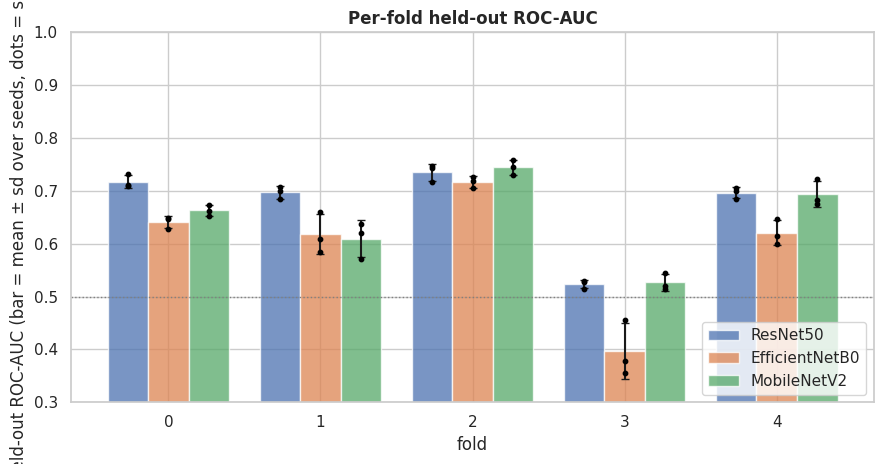

In [5]:
# ==============================================================================
# SECTION 4.2.4: COMPARATIVE CV SUMMARY AND PER-FOLD AUC
# ==============================================================================
# CHAPTER 3: Evaluation (cross-validation mean and sd, pooled out-of-fold, bootstrap interval)
rows = []
for a in ARCHS:
    r = RUNS[a]
    pooled = pd.DataFrame([dict(seed=s, **dict(zip(M5, five(g.label.values.astype(int), g.pred.values.astype(int), g.prob.values)))) for s, g in OOF[a].groupby("seed")])
    for m in M5:
        e, lo, hi = ci("oof", a, m)
        rows.append(dict(arch=a, metric=m, heldout_mean=r["heldout_" + m].mean(), heldout_sd=r["heldout_" + m].std(ddof=1), n_runs=len(r), pooled_mean=pooled[m].mean(), pooled_sd=pooled[m].std(ddof=1),
                         n_seeds=len(pooled), pooled_stacked_estimate=e, pooled_ci_low=lo, pooled_ci_high=hi))
CVN = pd.DataFrame(rows); savetab(CVN.round(4), "t4_2_4_cv_comparison_numeric.csv", "4.2.4", "Comparative CV summary, numeric values")
txt = {}
for blk, f in [("Held-out (mean ± sd, 15 runs)", lambda r: pm(r.heldout_mean, r.heldout_sd)), ("Pooled out-of-fold (mean ± sd, 3 seeds)", lambda r: pm(r.pooled_mean, r.pooled_sd)),
               ("Pooled out-of-fold bootstrap 95% CI", lambda r: f"[{r.pooled_ci_low:.3f}, {r.pooled_ci_high:.3f}]")]:
    for r in CVN.itertuples(): txt.setdefault((blk, MLAB[r.metric]), {})[dn(r.arch)] = f(r)
cvw = pd.DataFrame(txt).T[[dn(a) for a in ARCHS]]; cvw.index.names = ["block", "metric"]
cvw = cvw.reindex(pd.MultiIndex.from_product([["Held-out (mean ± sd, 15 runs)", "Pooled out-of-fold (mean ± sd, 3 seeds)", "Pooled out-of-fold bootstrap 95% CI"], [MLAB[m] for m in M5]], names=["block", "metric"]))
savetab(cvw.reset_index(), "t4_2_4_cv_comparison.csv", "4.2.4", "Comparative CV summary, three architectures side by side (mean ± sd and bootstrap CI)"); display(cvw)

rows = []
for a in ARCHS:
    r = RUNS[a]; am = r.heldout_roc_auc.mean()
    for f, g in r.groupby("fold"):
        g = g.sort_values("seed"); row = dict(arch=a, fold=int(f), auc_mean=g.heldout_roc_auc.mean(), auc_sd=g.heldout_roc_auc.std(ddof=1), auc_min=g.heldout_roc_auc.min(), auc_max=g.heldout_roc_auc.max(),
                                              delta_vs_arch_mean=g.heldout_roc_auc.mean() - am, n_heldout=int(g.n_heldout.iloc[0]), n_theta_fallback=int(g.theta_fallback.sum()) if "theta_fallback" in g else np.nan)
        for s, v in zip(g.seed, g.heldout_roc_auc): row[f"auc_seed_{int(s)}"] = v
        rows.append(row)
PF = pd.DataFrame(rows); PF["unstable"] = PF.groupby("arch").auc_mean.transform(lambda s: (s - s.mean()).abs() > 1.5 * s.std(ddof=1)) | (PF.n_theta_fallback > 0)
savetab(PF.round(4), "t4_2_4_per_fold_auc.csv", "4.2.4", "Per-fold held-out ROC-AUC (mean, sd and every seed), unstable folds flagged")
pw = PF.assign(txt=lambda d: d.auc_mean.map("{:.3f}".format) + " ± " + d.auc_sd.map("{:.3f}".format) + np.where(d.unstable, " *", "")).pivot(index="fold", columns="arch", values="txt")[ARCHS].rename(columns=dn)
print("\nHeld-out ROC-AUC per fold (mean ± sd over seeds). * = fold more than 1.5 sd from the model's fold mean, or a validation threshold fell back to 0.5"); display(pw)
for a in ARCHS:
    g = PF[PF.arch == a]; print(f"  {dn(a):16s} fold range {g.auc_mean.min():.3f} to {g.auc_mean.max():.3f}; weakest fold {int(g.loc[g.auc_mean.idxmin(), 'fold'])}; unstable folds: {[int(f) for f in g[g.unstable].fold] or 'none'}")

fig, ax = plt.subplots(figsize=(9, 4.8)); w = 0.8 / len(ARCHS)
for i, a in enumerate(ARCHS):
    g = PF[PF.arch == a].sort_values("fold"); x = g.fold.values + (i - (len(ARCHS) - 1) / 2) * w
    ax.bar(x, g.auc_mean, w, yerr=g.auc_sd, capsize=3, color=col(a), alpha=0.75, label=dn(a))
    for s in [c for c in g.columns if c.startswith("auc_seed_")]: ax.scatter(x, g[s], color="black", s=10, zorder=3)
ax.axhline(0.5, color="grey", ls=":", lw=1); ax.set_xticks(range(N_FOLDS)); ax.set_xlabel("fold"); ax.set_ylabel("held-out ROC-AUC (bar = mean ± sd over seeds, dots = seeds)"); ax.set_ylim(0.3, 1); ax.legend(loc="lower right")
ax.set_title("Per-fold held-out ROC-AUC", fontweight="bold"); savefig("f4_2_4_per_fold_auc.png", "4.2.4", "Per-fold held-out ROC-AUC of the three architectures")

## 4.3 Thresholds
The frozen θ of each run is the Youden threshold fixed on the validation set. The sensitivity table scores every run and every final model at the frozen θ and at 0.3, 0.5 and 0.7. ROC-AUC does not depend on the threshold, so it is not repeated here.

arch,resnet50,efficientnet_b0,mobilenet_v2
theta_mean,0.467,0.406,0.44
theta_sd,0.044,0.091,0.075
theta_min,0.396,0.266,0.302
theta_max,0.517,0.601,0.55
n_runs,15,15,15
n_fallback_to_0_5,0,0,0
theta_fold_0,0.5,0.44,0.481
theta_fold_1,0.447,0.303,0.348
theta_fold_2,0.476,0.42,0.413
theta_fold_3,0.409,0.385,0.478


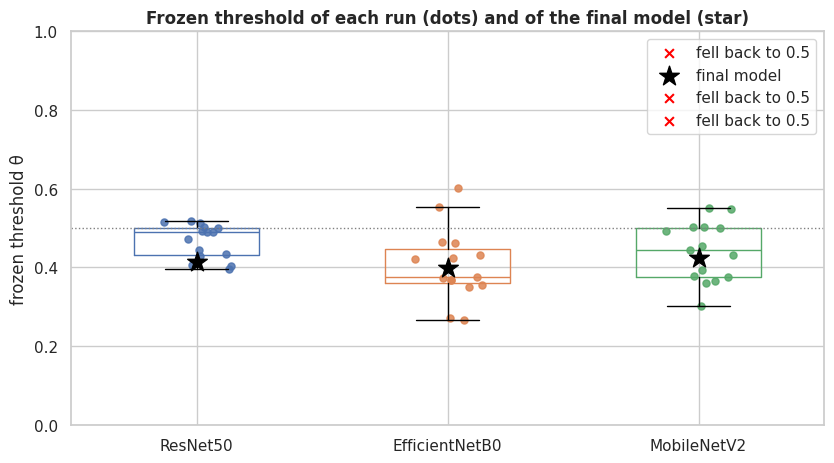


held-out, 15 CV runs (mean ± sd over runs; the final model is a single value)


ResNet50 EfficientNetB0    MobileNetV2
threshold metric                                                
frozen θ  Accuracy   0.603 ± 0.061  0.524 ± 0.106  0.584 ± 0.093
          Precision  0.560 ± 0.216  0.483 ± 0.228  0.514 ± 0.256
          Recall     0.555 ± 0.184  0.590 ± 0.257  0.542 ± 0.297
          F1         0.529 ± 0.157  0.488 ± 0.215  0.480 ± 0.224
0.3       Accuracy   0.577 ± 0.129  0.535 ± 0.140  0.590 ± 0.114
          Precision  0.509 ± 0.173  0.461 ± 0.210  0.515 ± 0.166
          Recall     0.928 ± 0.062  0.782 ± 0.241  0.951 ± 0.039
          F1         0.642 ± 0.156  0.572 ± 0.227  0.654 ± 0.147
0.5       Accuracy   0.627 ± 0.055  0.605 ± 0.041  0.593 ± 0.041
          Precision  0.544 ± 0.268  0.536 ± 0.244  0.528 ± 0.298
          Recall     0.419 ± 0.221  0.380 ± 0.168  0.318 ± 0.175
          F1         0.464 ± 0.226  0.434 ± 0.188  0.387 ± 0.203
0.7       Accuracy   0.569 ± 0.145  0.559 ± 0.147  0.560 ± 0.150
          Precision  0.688 ± 0.403  0.560 ± 0.460  0.267 ± 0.458
          Recall     0.038 ± 0.031  0.037 ± 0.037  0.012 ± 0.022
          F1         0.070 ± 0.054  0.067 ± 0.064  0.022 ± 0.042


external test, 15 models (mean ± sd over runs; the final model is a single value)


ResNet50 EfficientNetB0    MobileNetV2
threshold metric                                                
frozen θ  Accuracy   0.650 ± 0.024  0.638 ± 0.049  0.662 ± 0.058
          Precision  0.606 ± 0.039  0.596 ± 0.081  0.655 ± 0.101
          Recall     0.656 ± 0.075  0.769 ± 0.197  0.667 ± 0.210
          F1         0.626 ± 0.026  0.645 ± 0.084  0.627 ± 0.088
0.3       Accuracy   0.547 ± 0.042  0.579 ± 0.032  0.531 ± 0.032
          Precision  0.500 ± 0.025  0.518 ± 0.022  0.490 ± 0.018
          Recall     0.912 ± 0.063  0.960 ± 0.026  0.929 ± 0.028
          F1         0.644 ± 0.020  0.673 ± 0.017  0.641 ± 0.019
0.5       Accuracy   0.665 ± 0.016  0.689 ± 0.026  0.703 ± 0.020
          Precision  0.639 ± 0.034  0.678 ± 0.040  0.742 ± 0.038
          Recall     0.599 ± 0.052  0.595 ± 0.052  0.527 ± 0.072
          F1         0.616 ± 0.019  0.632 ± 0.034  0.612 ± 0.050
0.7       Accuracy   0.583 ± 0.025  0.601 ± 0.031  0.559 ± 0.005
          Precision  0.817 ± 0.269  0.873 ± 0.255  0.933 ± 0.258
          Recall     0.086 ± 0.057  0.122 ± 0.070  0.021 ± 0.010
          F1         0.153 ± 0.095  0.209 ± 0.113  0.040 ± 0.019


external test, final model (mean ± sd over runs; the final model is a single value)


ResNet50 EfficientNetB0 MobileNetV2
threshold metric                                       
frozen θ  Accuracy     0.617          0.706       0.722
          Precision    0.567          0.637       0.670
          Recall       0.630          0.802       0.753
          F1           0.596          0.710       0.709
0.3       Accuracy     0.606          0.644       0.600
          Precision    0.540          0.562       0.531
          Recall       0.827          0.951       0.938
          F1           0.654          0.706       0.679
0.5       Accuracy     0.656          0.728       0.722
          Precision    0.651          0.729       0.782
          Recall       0.506          0.630       0.531
          F1           0.569          0.675       0.632
0.7       Accuracy     0.594          0.622       0.567
          Precision    0.833          1.000       1.000
          Recall       0.123          0.160       0.037
          F1           0.215          0.277       0.071

In [6]:
# ==============================================================================
# SECTION 4.3: FROZEN THRESHOLDS, SPREAD AND FIXED-THRESHOLD RESULTS
# ==============================================================================
# CHAPTER 3: Evaluation (Youden threshold frozen on validation, sensitivity at 0.3, 0.5 and 0.7)
rows = []
for a in ARCHS:
    r = RUNS[a]; f = FINROW[a].iloc[0]; row = dict(arch=a, theta_mean=r.theta.mean(), theta_sd=r.theta.std(ddof=1), theta_min=r.theta.min(), theta_max=r.theta.max(), n_runs=len(r),
                                                    n_fallback_to_0_5=int(r.theta_fallback.sum()) if "theta_fallback" in r else np.nan)
    for fo, v in r.groupby("fold").theta.mean().items(): row[f"theta_fold_{int(fo)}"] = v
    row["final_model_theta"] = f.get("threshold", np.nan); row["final_model_theta_source"] = f.get("threshold_source", ""); row["final_model_theta_fallback"] = f.get("threshold_fallback", np.nan)
    rows.append(row)
TH = pd.DataFrame(rows); savetab(TH.round(4), "t4_3_thresholds.csv", "4.3", "Frozen threshold and its spread over the 15 runs, and the final model threshold"); display(TH.round(3).set_index("arch").T)

fig, ax = plt.subplots(figsize=(8.5, 4.8)); fb_label = False
for i, a in enumerate(ARCHS):
    r = RUNS[a]; x = np.full(len(r), i) + np.random.RandomState(0).uniform(-0.15, 0.15, len(r)); ax.boxplot(r.theta.values, positions=[i], widths=0.5, showfliers=False, boxprops=dict(color=col(a)), medianprops=dict(color=col(a)))
    fbm = r.theta_fallback.astype(bool).values if "theta_fallback" in r else np.zeros(len(r), bool)
    ax.scatter(x[~fbm], r.theta.values[~fbm], color=col(a), s=26, alpha=0.85); ax.scatter(x[fbm], r.theta.values[fbm], color="red", marker="x", s=40, label="fell back to 0.5" if not fb_label else None); fb_label |= fbm.any()
    ax.scatter([i], [TH.set_index("arch").loc[a, "final_model_theta"]], marker="*", s=220, color="black", zorder=4, label="final model" if i == 0 else None)
ax.axhline(0.5, color="grey", ls=":", lw=1); ax.set_xticks(range(len(ARCHS))); ax.set_xticklabels([dn(a) for a in ARCHS]); ax.set_ylabel("frozen threshold θ"); ax.set_ylim(0, 1); ax.legend()
ax.set_title("Frozen threshold of each run (dots) and of the final model (star)", fontweight="bold"); savefig("f4_3_threshold_spread.png", "4.3", "Spread of the frozen threshold per architecture")

def at_thr(g, t=None):
    y = g.label.values.astype(int); pr = g.pred.values.astype(int) if t is None else (g.prob.values >= t).astype(int); v = five(y, pr, g.prob.values); return dict(zip(M5, v))
rows = []
for a in ARCHS:
    for ev, src in [("held-out, 15 CV runs", OOF[a]), ("external test, 15 models", TST[a])]:
        for tn, t in [("frozen θ", None)] + [(str(x), x) for x in FIXED_THRESHOLDS]:
            per = pd.DataFrame([at_thr(g, t) for _, g in src.groupby("run_id")])
            rows.append(dict(arch=a, evaluated_on=ev, threshold=tn, n=len(per), **{f"{m}_mean": per[m].mean() for m in M5[:4]}, **{f"{m}_sd": per[m].std(ddof=1) for m in M5[:4]}))
    for tn, t in [("frozen θ", None)] + [(str(x), x) for x in FIXED_THRESHOLDS]:
        v = at_thr(FIN[a], t); rows.append(dict(arch=a, evaluated_on="external test, final model", threshold=tn, n=1, **{f"{m}_mean": v[m] for m in M5[:4]}, **{f"{m}_sd": np.nan for m in M5[:4]}))
TS = pd.DataFrame(rows); savetab(TS.round(4), "t4_3_fixed_thresholds.csv", "4.3", "Accuracy, precision, recall and F1 at the frozen theta and at 0.3, 0.5, 0.7 for CV runs and final models")
order = ["frozen θ"] + [str(x) for x in FIXED_THRESHOLDS]
for ev in ["held-out, 15 CV runs", "external test, 15 models", "external test, final model"]:
    t = TS[TS.evaluated_on == ev]; cells_ = {}
    for r in t.itertuples():
        for m in M5[:4]: cells_.setdefault((r.threshold, MLAB[m]), {})[dn(r.arch)] = f"{getattr(r, m + '_mean'):.3f}" + ("" if r.n == 1 else f" ± {getattr(r, m + '_sd'):.3f}")
    w_ = pd.DataFrame(cells_).T[[dn(a) for a in ARCHS]]; w_ = w_.reindex(pd.MultiIndex.from_product([order, [MLAB[m] for m in M5[:4]]])); w_.index.names = ["threshold", "metric"]
    print(f"\n{ev} (mean ± sd over runs; the final model is a single value)"); display(w_)

## 4.4 Test set
The test set is unseen by the models, but some sellers and sources also appear in the training pool, so the numbers are somewhat optimistic. The 15-model rows summarise how the architecture performs over folds and seeds. The final model is the single packaged model.

ResNet50  \
block                          metric                            
15-model mean ± sd             Accuracy          0.650 ± 0.024   
                               Precision         0.606 ± 0.039   
                               Recall            0.656 ± 0.075   
                               F1                0.626 ± 0.026   
                               ROC-AUC           0.719 ± 0.016   
15-model bootstrap 95% CI      Accuracy         [0.533, 0.740]   
                               Precision        [0.156, 0.775]   
                               Recall           [0.479, 0.854]   
                               F1               [0.256, 0.780]   
                               ROC-AUC          [0.595, 0.841]   
Final model [bootstrap 95% CI] Accuracy   0.617 [0.467, 0.719]   
                               Precision  0.567 [0.150, 0.758]   
                               Recall     0.630 [0.429, 0.946]   
                               F1         0.596 [0.255, 0.767]   
                               ROC-AUC    0.718 [0.581, 0.876]   

                                                EfficientNetB0  \
block                          metric                            
15-model mean ± sd             Accuracy          0.638 ± 0.049   
                               Precision         0.596 ± 0.081   
                               Recall            0.769 ± 0.197   
                               F1                0.645 ± 0.084   
                               ROC-AUC           0.765 ± 0.028   
15-model bootstrap 95% CI      Accuracy         [0.511, 0.733]   
                               Precision        [0.159, 0.735]   
                               Recall           [0.639, 0.920]   
                               F1               [0.266, 0.793]   
                               ROC-AUC          [0.661, 0.883]   
Final model [bootstrap 95% CI] Accuracy   0.706 [0.573, 0.830]   
                               Precision  0.637 [0.204, 0.796]   
                               Recall     0.802 [0.610, 1.000]   
                               F1         0.710 [0.339, 0.868]   
                               ROC-AUC    0.823 [0.720, 0.940]   

                                                   MobileNetV2  
block                          metric                           
15-model mean ± sd             Accuracy          0.662 ± 0.058  
                               Precision         0.655 ± 0.101  
                               Recall            0.667 ± 0.210  
                               F1                0.627 ± 0.088  
                               ROC-AUC           0.760 ± 0.017  
15-model bootstrap 95% CI      Accuracy         [0.602, 0.746]  
                               Precision        [0.185, 0.773]  
                               Recall           [0.521, 0.863]  
                               F1               [0.303, 0.786]  
                               ROC-AUC          [0.643, 0.895]  
Final model [bootstrap 95% CI] Accuracy   0.722 [0.623, 0.828]  
                               Precision  0.670 [0.194, 0.817]  
                               Recall     0.753 [0.548, 1.000]  
                               F1         0.709 [0.324, 0.864]  
                               ROC-AUC    0.798 [0.681, 0.934]

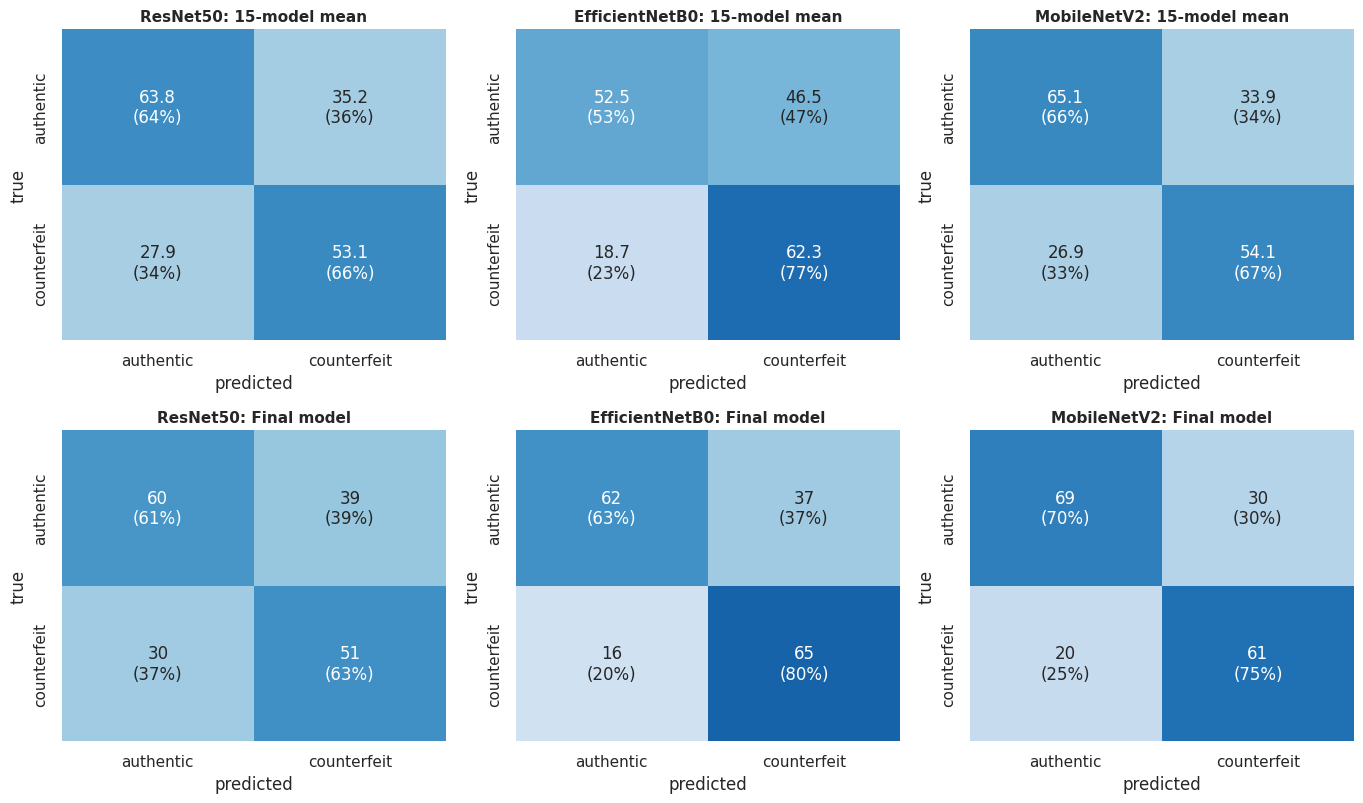

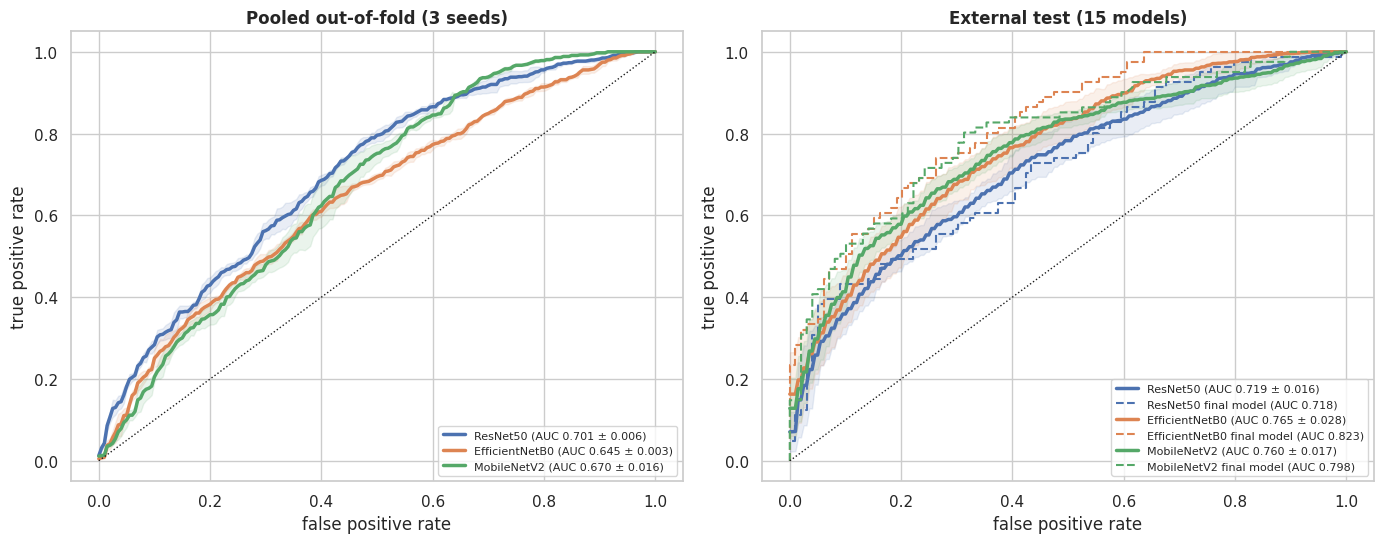

In [7]:
# ==============================================================================
# SECTION 4.4: TEST SET SUMMARY, CONFUSION MATRICES, ROC CURVES
# ==============================================================================
# CHAPTER 3: Evaluation (external test set, confusion matrices, ROC curves)
rows = []
for a in ARCHS:
    r = RUNS[a]
    for m in M5:
        e, lo, hi = ci("test", a, m); fe, flo, fhi = ci("final", a, m)
        rows.append(dict(arch=a, metric=m, test_mean=r["test_" + m].mean(), test_sd=r["test_" + m].std(ddof=1), n_runs=len(r), stacked_estimate=e, ci_low=lo, ci_high=hi, final_model=fe, final_ci_low=flo, final_ci_high=fhi,
                         cv_heldout_mean=r["heldout_" + m].mean(), drop_cv_minus_test=(r["heldout_" + m] - r["test_" + m]).mean(), drop_sd=(r["heldout_" + m] - r["test_" + m]).std(ddof=1)))
TN = pd.DataFrame(rows); savetab(TN.round(4), "t4_4_test_summary_numeric.csv", "4.4", "Test results, numeric values")
txt = {}
for r in TN.itertuples():
    for blk, v in [("15-model mean ± sd", pm(r.test_mean, r.test_sd)), ("15-model bootstrap 95% CI", f"[{r.ci_low:.3f}, {r.ci_high:.3f}]"), ("Final model [bootstrap 95% CI]", f"{r.final_model:.3f} [{r.final_ci_low:.3f}, {r.final_ci_high:.3f}]")]:
        txt.setdefault((blk, MLAB[r.metric]), {})[dn(r.arch)] = v
blocks = ["15-model mean ± sd", "15-model bootstrap 95% CI", "Final model [bootstrap 95% CI]"]
tw = pd.DataFrame(txt).T[[dn(a) for a in ARCHS]].reindex(pd.MultiIndex.from_product([blocks, [MLAB[m] for m in M5]], names=["block", "metric"]))
savetab(tw.reset_index(), "t4_4_test_summary.csv", "4.4", "External test results: 15-model mean ± sd, bootstrap CIs and the final model, side by side"); display(tw)
dr = TN[TN.metric.isin(["accuracy", "f1", "roc_auc"])][["arch", "metric", "cv_heldout_mean", "test_mean", "drop_cv_minus_test", "drop_sd"]]
savetab(dr.round(4), "t4_4_cv_to_test_drop.csv", "4.4", "Change from the held-out folds to the external test set (positive = lower on test)")

def cm_counts(g): 
    y, pr = g.label.values.astype(int), g.pred.values.astype(int); return np.array([[((y == 0) & (pr == 0)).sum(), ((y == 0) & (pr == 1)).sum()], [((y == 1) & (pr == 0)).sum(), ((y == 1) & (pr == 1)).sum()]])
CMS = {}; rows = []
for a in ARCHS:
    CMS[(a, "15")] = np.mean([cm_counts(g) for _, g in TST[a].groupby("run_id")], axis=0); CMS[(a, "final")] = cm_counts(FIN[a])
    for kind, nm in [("15", "15-model mean (per model)"), ("final", "final model")]:
        for i, t_ in enumerate(["authentic", "counterfeit"]):
            for j, p_ in enumerate(["authentic", "counterfeit"]): rows.append(dict(arch=a, model=nm, true=t_, predicted=p_, count=CMS[(a, kind)][i, j]))
savetab(pd.DataFrame(rows).round(3), "t4_4_confusion_matrices.csv", "4.4", "Confusion matrices on the external test set: 15-model mean and final model")
fig, axes = plt.subplots(2, len(ARCHS), figsize=(4.6 * len(ARCHS), 8.2), squeeze=False)
for r_, (kind, nm) in enumerate([("15", "15-model mean"), ("final", "Final model")]):
    for c_, a in enumerate(ARCHS):
        cm = CMS[(a, kind)]; share = cm / cm.sum(1, keepdims=True)
        sns.heatmap(share, annot=np.array([[f"{cm[i, j]:.1f}\n({share[i, j]:.0%})" if kind == "15" else f"{int(cm[i, j])}\n({share[i, j]:.0%})" for j in range(2)] for i in range(2)]), fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=axes[r_, c_],
                    xticklabels=["authentic", "counterfeit"], yticklabels=["authentic", "counterfeit"], annot_kws=dict(fontsize=12))
        axes[r_, c_].set_title(f"{dn(a)}: {nm}", fontweight="bold", fontsize=11); axes[r_, c_].set_xlabel("predicted"); axes[r_, c_].set_ylabel("true")
savefig("f4_4_confusion_matrices.png", "4.4", "Confusion matrices on the external test set, three architectures side by side (counts, row percentages)")

def mean_roc(groups):
    grid = np.linspace(0, 1, 201); tprs = []
    for g in groups: fpr, tpr, _ = roc_curve(g.label.values, g.prob.values); tprs.append(np.interp(grid, fpr, tpr))
    return grid, np.mean(tprs, 0), np.std(tprs, 0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, (src, by, title) in zip(axes, [(OOF, "seed", "Pooled out-of-fold (3 seeds)"), (TST, "run_id", "External test (15 models)")]):
    for a in ARCHS:
        gs = [g for _, g in src[a].groupby(by)]; aucs = np.array([fast_auc(g.label.values.astype(int), g.prob.values) for g in gs]); grid, mu, sd = mean_roc(gs)
        ax.plot(grid, mu, color=col(a), lw=2.5, label=f"{dn(a)} (AUC {aucs.mean():.3f} ± {aucs.std(ddof=1):.3f})"); ax.fill_between(grid, np.maximum(mu - sd, 0), np.minimum(mu + sd, 1), color=col(a), alpha=0.12)
        if src is TST:
            fpr, tpr, _ = roc_curve(FIN[a].label.values, FIN[a].prob.values); ax.plot(fpr, tpr, color=col(a), lw=1.5, ls="--", label=f"{dn(a)} final model (AUC {ci('final', a, 'roc_auc')[0]:.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.set_title(title, fontweight="bold"); ax.legend(loc="lower right", fontsize=8)
savefig("f4_4_roc_curves.png", "4.4", "ROC curves of the three architectures on shared axes, pooled out-of-fold and external test (AUC in legend)")

## 4.5 Statistical comparison
**Primary test.** Paired group bootstrap of the A − B difference in ROC-AUC, accuracy, F1 and recall. Both models are scored on the same resampled groups. The 3 pairwise comparisons are Holm-corrected within each evaluation set and metric, and the Holm-adjusted interval uses the confidence level 1 − α / (3 − rank + 1) for the comparison of that rank (rank 1 = smallest raw p). **An architecture is labelled better only when its Holm-adjusted interval excludes zero and the Holm-adjusted p is below α. Otherwise the table says "no reliable difference".**

**McNemar.** Exact test on the final models' test predictions and on the out-of-fold predictions of each seed separately (one prediction per image). It is not run on the stacked 15 models, because that would multiply the sample size. Holm correction over the 3 pairs within each view. Images from the same group are not independent, so McNemar p-values are optimistic and the bootstrap is the more conservative test.

**Nadeau-Bengio.** Optional corrected resampled t-test on the 15 paired held-out AUCs, with the variance inflated by 1/15 + n_test/n_train.


pooled out-of-fold (3 seeds stacked)


,metric,pair,diff,CI95,Holm_CI,p_holm,verdict
0,roc_auc,ResNet50 - EfficientNetB0,+0.055,"[-0.010, +0.104]","[-0.036, +0.122]",0.273,no reliable difference
1,roc_auc,ResNet50 - MobileNetV2,+0.031,"[-0.007, +0.067]","[-0.016, +0.077]",0.273,no reliable difference
2,roc_auc,EfficientNetB0 - MobileNetV2,-0.025,"[-0.074, +0.033]","[-0.074, +0.033]",0.372,no reliable difference
3,accuracy,ResNet50 - EfficientNetB0,+0.072,"[-0.005, +0.168]","[-0.022, +0.188]",0.126,no reliable difference
4,accuracy,ResNet50 - MobileNetV2,+0.034,"[-0.036, +0.089]","[-0.036, +0.089]",0.288,no reliable difference
5,accuracy,EfficientNetB0 - MobileNetV2,-0.038,"[-0.103, -0.007]","[-0.115, +0.003]",0.075,no reliable difference
6,f1,ResNet50 - EfficientNetB0,+0.008,"[-0.066, +0.105]","[-0.077, +0.117]",1.000,no reliable difference
7,f1,ResNet50 - MobileNetV2,+0.015,"[-0.059, +0.071]","[-0.089, +0.084]",1.000,no reliable difference
8,f1,EfficientNetB0 - MobileNetV2,+0.007,"[-0.055, +0.040]","[-0.055, +0.040]",1.000,no reliable difference
9,recall,ResNet50 - EfficientNetB0,-0.077,"[-0.176, +0.046]","[-0.196, +0.064]",0.417,no reliable difference



external test (15 models stacked)


,metric,pair,diff,CI95,Holm_CI,p_holm,verdict
0,roc_auc,ResNet50 - EfficientNetB0,-0.049,"[-0.118, -0.004]","[-0.144, +0.009]",0.111,no reliable difference
1,roc_auc,ResNet50 - MobileNetV2,-0.044,"[-0.123, +0.005]","[-0.140, +0.011]",0.178,no reliable difference
2,roc_auc,EfficientNetB0 - MobileNetV2,+0.005,"[-0.065, +0.047]","[-0.065, +0.047]",0.813,no reliable difference
3,accuracy,ResNet50 - EfficientNetB0,+0.012,"[-0.045, +0.082]","[-0.045, +0.082]",1.000,no reliable difference
4,accuracy,ResNet50 - MobileNetV2,-0.012,"[-0.113, +0.027]","[-0.131, +0.033]",1.000,no reliable difference
5,accuracy,EfficientNetB0 - MobileNetV2,-0.024,"[-0.130, +0.023]","[-0.153, +0.030]",1.000,no reliable difference
6,f1,ResNet50 - EfficientNetB0,-0.029,"[-0.065, +0.028]","[-0.073, +0.045]",0.879,no reliable difference
7,f1,ResNet50 - MobileNetV2,-0.012,"[-0.066, +0.017]","[-0.075, +0.023]",0.879,no reliable difference
8,f1,EfficientNetB0 - MobileNetV2,+0.017,"[-0.063, +0.051]","[-0.063, +0.051]",0.879,no reliable difference
9,recall,ResNet50 - EfficientNetB0,-0.113,"[-0.160, -0.037]","[-0.162, -0.027]",0.021,EfficientNetB0 better



external test (final model)


,metric,pair,diff,CI95,Holm_CI,p_holm,verdict
0,roc_auc,ResNet50 - EfficientNetB0,-0.104,"[-0.184, -0.031]","[-0.211, -0.019]",0.008,EfficientNetB0 better
1,roc_auc,ResNet50 - MobileNetV2,-0.080,"[-0.139, -0.029]","[-0.158, -0.019]",0.003,MobileNetV2 better
2,roc_auc,EfficientNetB0 - MobileNetV2,+0.024,"[-0.029, +0.073]","[-0.029, +0.073]",0.304,no reliable difference
3,accuracy,ResNet50 - EfficientNetB0,-0.089,"[-0.185, -0.030]","[-0.200, -0.019]",0.026,EfficientNetB0 better
4,accuracy,ResNet50 - MobileNetV2,-0.106,"[-0.213, -0.049]","[-0.238, -0.038]",0.009,MobileNetV2 better
5,accuracy,EfficientNetB0 - MobileNetV2,-0.017,"[-0.084, +0.022]","[-0.084, +0.022]",0.468,no reliable difference
6,f1,ResNet50 - EfficientNetB0,-0.114,"[-0.168, -0.043]","[-0.182, -0.027]",0.022,EfficientNetB0 better
7,f1,ResNet50 - MobileNetV2,-0.113,"[-0.170, -0.047]","[-0.189, -0.032]",0.021,MobileNetV2 better
8,f1,EfficientNetB0 - MobileNetV2,+0.001,"[-0.047, +0.033]","[-0.047, +0.033]",0.919,no reliable difference
9,recall,ResNet50 - EfficientNetB0,-0.173,"[-0.259, -0.050]","[-0.262, +0.000]",0.081,no reliable difference


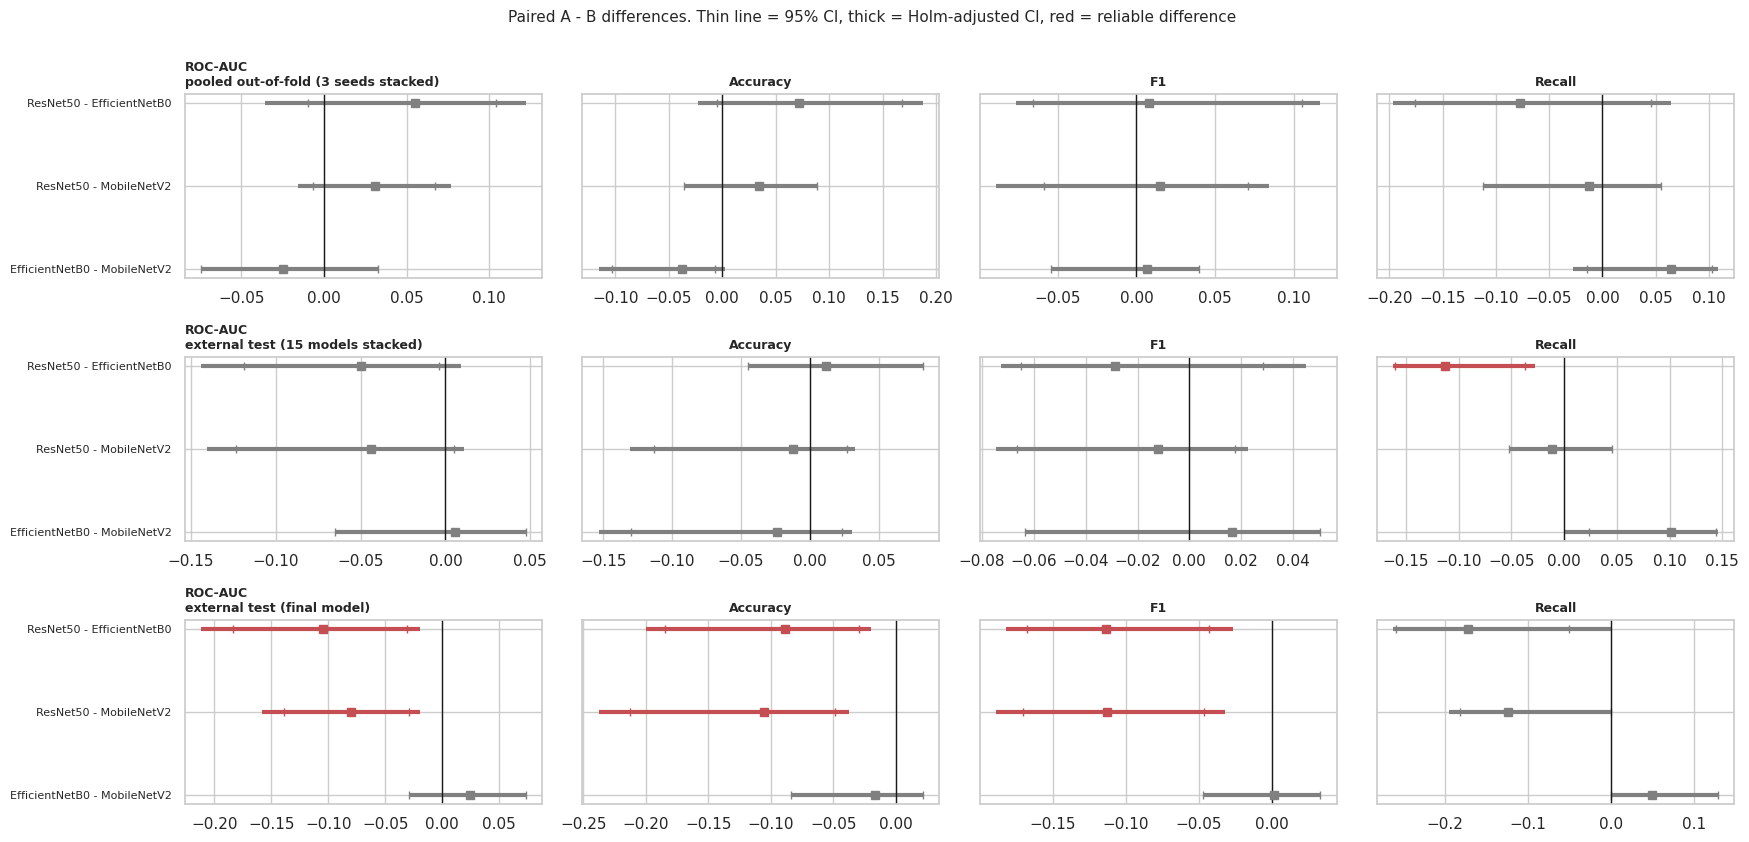

,view,model_a,model_b,n_images,acc_a,acc_b,only_a_correct,only_b_correct,p_mcnemar,p_holm,verdict
0,"final model, external test",ResNet50,EfficientNetB0,180,0.6167,0.7056,18,34,0.0365,0.0730,no reliable difference
1,"final model, external test",ResNet50,MobileNetV2,180,0.6167,0.7222,14,33,0.0079,0.0238,MobileNetV2 better
2,"final model, external test",EfficientNetB0,MobileNetV2,180,0.7056,0.7222,15,18,0.7283,0.7283,no reliable difference
3,"out-of-fold, seed 42",ResNet50,EfficientNetB0,555,0.6252,0.5369,127,78,0.0008,0.0023,ResNet50 better
4,"out-of-fold, seed 42",ResNet50,MobileNetV2,555,0.6252,0.5892,101,81,0.1588,0.1588,no reliable difference
5,"out-of-fold, seed 42",EfficientNetB0,MobileNetV2,555,0.5369,0.5892,57,86,0.0189,0.0378,MobileNetV2 better
6,"out-of-fold, seed 1337",ResNet50,EfficientNetB0,555,0.6126,0.5387,98,57,0.0012,0.0037,ResNet50 better
7,"out-of-fold, seed 1337",ResNet50,MobileNetV2,555,0.6126,0.5928,66,55,0.3634,0.3634,no reliable difference
8,"out-of-fold, seed 1337",EfficientNetB0,MobileNetV2,555,0.5387,0.5928,38,68,0.0046,0.0092,MobileNetV2 better
9,"out-of-fold, seed 2024",ResNet50,EfficientNetB0,555,0.6000,0.5459,121,91,0.0461,0.0923,no reliable difference


,model_a,model_b,n_pairs,mean_auc_diff,n_test_over_n_train,t,df,p_nb,p_holm,verdict
0,ResNet50,EfficientNetB0,15,0.0754,0.336,2.5651,14,0.0224,0.0673,no reliable difference
1,ResNet50,MobileNetV2,15,0.0265,0.336,0.9119,14,0.3773,0.4111,no reliable difference
2,EfficientNetB0,MobileNetV2,15,-0.0489,0.336,-1.3276,14,0.2056,0.4111,no reliable difference


In [8]:
# ==============================================================================
# SECTION 4.5.1: PAIRED GROUP BOOTSTRAP OF THE DIFFERENCES
# ==============================================================================
# CHAPTER 3: Evaluation (paired group bootstrap, Holm correction)
PAIR_METRICS = ["roc_auc", "accuracy", "f1", "recall"]
def verdict(a, b, diff, adj_lo, adj_hi, reliable):
    return (f"{dn(a)} better" if diff > 0 else f"{dn(b)} better") if reliable else "no reliable difference"

pair_rows = []
for k in W:
    for m in PAIR_METRICS:
        mi = M5.index(m); prs = []
        for a, b in itertools.combinations(ARCHS, 2):
            d = DRAWS[k][a][:, mi] - DRAWS[k][b][:, mi]; d = d[~np.isnan(d)]
            p = min(1.0, 2 * (min((d <= 0).sum(), (d >= 0).sum()) + 1) / (len(d) + 1))
            prs.append(dict(eval_set=SET_NAME[k], set_key=k, metric=m, model_a=a, model_b=b, est_a=EST[k][a][mi], est_b=EST[k][b][mi], diff_a_minus_b=EST[k][a][mi] - EST[k][b][mi],
                            ci_low=np.percentile(d, 2.5), ci_high=np.percentile(d, 97.5), p_boot=p, _d=d))
        padj = holm([r["p_boot"] for r in prs]); order_ = np.argsort([r["p_boot"] for r in prs], kind="stable")
        for rank, i in enumerate(order_):
            al = ALPHA / (len(prs) - rank); lo, hi = np.percentile(prs[i]["_d"], [100 * al / 2, 100 * (1 - al / 2)])
            prs[i].update(adj_level=1 - al, adj_ci_low=lo, adj_ci_high=hi, p_holm=padj[i])
        for r in prs:
            r["reliable"] = bool((r["adj_ci_low"] > 0 or r["adj_ci_high"] < 0) and r["p_holm"] < ALPHA)
            r["verdict"] = verdict(r["model_a"], r["model_b"], r["diff_a_minus_b"], r["adj_ci_low"], r["adj_ci_high"], r["reliable"]); r.pop("_d")
        pair_rows += prs
PAIRS = pd.DataFrame(pair_rows)
savetab(PAIRS.drop(columns="set_key").round(4), "t4_5_paired_bootstrap.csv", "4.5", "Paired group bootstrap of A-B differences (ROC-AUC, accuracy, F1, recall), Holm-adjusted intervals and verdicts")
show = PAIRS.assign(pair=lambda d: d.model_a.map(dn) + " - " + d.model_b.map(dn), diff=lambda d: d.diff_a_minus_b.map("{:+.3f}".format), CI95=lambda d: "[" + d.ci_low.map("{:+.3f}".format) + ", " + d.ci_high.map("{:+.3f}".format) + "]",
                    Holm_CI=lambda d: "[" + d.adj_ci_low.map("{:+.3f}".format) + ", " + d.adj_ci_high.map("{:+.3f}".format) + "]", p_holm=lambda d: d.p_holm.map("{:.3f}".format))
for k in W:
    print(f"\n{SET_NAME[k]}"); display(show[show.set_key == k][["metric", "pair", "diff", "CI95", "Holm_CI", "p_holm", "verdict"]].reset_index(drop=True))

fig, axes = plt.subplots(len(W), len(PAIR_METRICS), figsize=(4.4 * len(PAIR_METRICS), 2.6 * len(W) + 0.6), squeeze=False)
for r_, k in enumerate(W):
    for c_, m in enumerate(PAIR_METRICS):
        ax = axes[r_, c_]; s = PAIRS[(PAIRS.set_key == k) & (PAIRS.metric == m)].reset_index(drop=True)
        for i, r in s.iterrows():
            c = "#C44E52" if r.reliable else "grey"
            ax.errorbar(r.diff_a_minus_b, -i, xerr=[[r.diff_a_minus_b - r.ci_low], [r.ci_high - r.diff_a_minus_b]], fmt="none", ecolor=c, lw=1, capsize=3)
            ax.errorbar(r.diff_a_minus_b, -i, xerr=[[r.diff_a_minus_b - r.adj_ci_low], [r.adj_ci_high - r.diff_a_minus_b]], fmt="s", color=c, lw=3, ms=6, capsize=0)
        ax.axvline(0, color="k", lw=1); ax.set_yticks([-i for i in range(len(s))]); ax.set_yticklabels([f"{dn(r.model_a)} - {dn(r.model_b)}" for r in s.itertuples()] if c_ == 0 else [], fontsize=8)
        ax.set_title(f"{MLAB[m]}" + (f"\n{SET_NAME[k]}" if c_ == 0 else ""), fontsize=9, fontweight="bold", loc="left" if c_ == 0 else "center")
fig.suptitle("Paired A - B differences. Thin line = 95% CI, thick = Holm-adjusted CI, red = reliable difference", y=1.0, fontsize=11)
savefig("f4_5_paired_differences.png", "4.5", "Paired bootstrap differences between architectures with Holm-adjusted intervals")

# ---- McNemar ------------------------------------------------------------------------------------------------------------
mc_rows = []
views = [("final model, external test", W["final"])] + [(f"out-of-fold, seed {s}", W["oof"][W["oof"].seed == s]) for s in sorted(W["oof"].seed.unique())]
for vname, d in views:
    y = d["label"].values; rows_ = []
    for a, b in itertools.combinations(ARCHS, 2):
        ca, cb = d[f"pred_{a}"].values == y, d[f"pred_{b}"].values == y; n_a, n_b = int((ca & ~cb).sum()), int((~ca & cb).sum())
        rows_.append(dict(view=vname, model_a=a, model_b=b, n_images=len(d), acc_a=ca.mean(), acc_b=cb.mean(), only_a_correct=n_a, only_b_correct=n_b, p_mcnemar=binomtest(n_a, n_a + n_b, 0.5).pvalue if n_a + n_b else 1.0))
    for r, adj in zip(rows_, holm([r["p_mcnemar"] for r in rows_])):
        r["p_holm"] = adj; r["verdict"] = (f"{dn(r['model_a'])} better" if r["only_a_correct"] > r["only_b_correct"] else f"{dn(r['model_b'])} better") if adj < ALPHA else "no reliable difference"
    mc_rows += rows_
MCN = pd.DataFrame(mc_rows); savetab(MCN.round(4), "t4_5_mcnemar.csv", "4.5", "McNemar exact tests on the final models (test) and on the out-of-fold predictions of each seed, Holm-corrected")
display(MCN.assign(model_a=MCN.model_a.map(dn), model_b=MCN.model_b.map(dn)).round(4))

# ---- Nadeau-Bengio ------------------------------------------------------------------------------------------------------
if RUN_NB_TTEST:
    nb_rows = []; ratio = float(np.mean([(RUNS[a].n_heldout / RUNS[a].n_train).mean() for a in ARCHS]))
    for a, b in itertools.combinations(ARCHS, 2):
        m_ = RUNS[a][["seed", "fold", "heldout_roc_auc"]].merge(RUNS[b][["seed", "fold", "heldout_roc_auc"]], on=["seed", "fold"], suffixes=("_a", "_b")); d = (m_.heldout_roc_auc_a - m_.heldout_roc_auc_b).values; n = len(d)
        with np.errstate(divide="ignore", invalid="ignore"):
            t = d.mean() / np.sqrt((1 / n + ratio) * d.var(ddof=1)); p = 2 * stats.t.sf(abs(t), n - 1)
        nb_rows.append(dict(model_a=a, model_b=b, n_pairs=n, mean_auc_diff=d.mean(), n_test_over_n_train=ratio, t=t, df=n - 1, p_nb=p))
    for r, adj in zip(nb_rows, holm([r["p_nb"] for r in nb_rows])):
        r["p_holm"] = adj; r["verdict"] = (f"{dn(r['model_a'])} better" if r["mean_auc_diff"] > 0 else f"{dn(r['model_b'])} better") if adj < ALPHA else "no reliable difference"
    NB = pd.DataFrame(nb_rows); savetab(NB.round(4), "t4_5_nadeau_bengio.csv", "4.5", "Nadeau-Bengio corrected t-test on the 15 paired held-out AUCs, Holm-corrected")
    display(NB.assign(model_a=NB.model_a.map(dn), model_b=NB.model_b.map(dn)).round(4))

## 4.5.2 Literature
Scaffold for Table 1. Our metrics are filled in from the external test set. The literature rows are left empty for you.

In [9]:
# ==============================================================================
# SECTION 4.5.2: LITERATURE SCAFFOLD (Table 1 benchmarks)
# ==============================================================================
# CHAPTER 3: none (thesis table scaffold)
cols = ["source", "task", "dataset", "n_images", "architecture", "accuracy", "precision", "recall", "f1", "roc_auc", "notes"]
rows = []
n_pool, n_test = OOF[ARCHS[0]].image_id.nunique(), TST[ARCHS[0]].image_id.nunique()
for a in ARCHS:
    for kind, k, note in [("15-model mean, external test", None, "mean over 15 runs; bootstrap CIs in t4_4_test_summary.csv"), ("final model, external test", "final", "single packaged model; see t4_4_test_summary.csv for the CI")]:
        v = {m: (RUNS[a]["test_" + m].mean() if k is None else ci("final", a, m)[0]) for m in M5}
        rows.append(dict(source=f"This study ({kind})", task="authentic vs counterfeit analog watch images", dataset=f"{n_pool} pool images, {n_test} external test images", n_images=n_pool + n_test, architecture=dn(a), **{m: round(v[m], 3) for m in M5}, notes=note))
for i in range(1, 6): rows.append(dict(source=f"[add literature source {i}]", **{c: "" for c in cols[1:]}))
LIT = pd.DataFrame(rows)[cols]; savetab(LIT, "t4_5_2_literature_scaffold.csv", "4.5.2", "Scaffold for Table 1: our metrics filled in, literature columns left empty"); display(LIT.head(2 * len(ARCHS)))

,source,task,dataset,n_images,architecture,accuracy,precision,recall,f1,roc_auc,notes
0,"This study (15-model mean, external test)",authentic vs counterfeit analog watch images,"555 pool images, 180 external test images",735,ResNet50,0.65,0.606,0.656,0.626,0.719,mean over 15 runs; bootstrap CIs in t4_4_test_summary.csv
1,"This study (final model, external test)",authentic vs counterfeit analog watch images,"555 pool images, 180 external test images",735,ResNet50,0.617,0.567,0.63,0.596,0.718,single packaged model; see t4_4_test_summary.csv for the CI
2,"This study (15-model mean, external test)",authentic vs counterfeit analog watch images,"555 pool images, 180 external test images",735,EfficientNetB0,0.638,0.596,0.769,0.645,0.765,mean over 15 runs; bootstrap CIs in t4_4_test_summary.csv
3,"This study (final model, external test)",authentic vs counterfeit analog watch images,"555 pool images, 180 external test images",735,EfficientNetB0,0.706,0.637,0.802,0.71,0.823,single packaged model; see t4_4_test_summary.csv for the CI
4,"This study (15-model mean, external test)",authentic vs counterfeit analog watch images,"555 pool images, 180 external test images",735,MobileNetV2,0.662,0.655,0.667,0.627,0.76,mean over 15 runs; bootstrap CIs in t4_4_test_summary.csv
5,"This study (final model, external test)",authentic vs counterfeit analog watch images,"555 pool images, 180 external test images",735,MobileNetV2,0.722,0.67,0.753,0.709,0.798,single packaged model; see t4_4_test_summary.csv for the CI


## 4.5.3 Error patterns
Counterfeit is the positive class, so a false negative is a counterfeit called authentic and a false positive is an authentic image called counterfeit. Rates use the stacked predictions of each evaluation set. An image counts as missed by a model when the majority of that model's predictions for the image are wrong (strict majority of the 3 seeds for the pool, of the 15 models for the test set), or when the final model is wrong.


External test (15 models stacked): error rates by brand


,,FNR ResNet50,FNR EfficientNetB0,FNR MobileNetV2,FPR ResNet50,FPR EfficientNetB0,FPR MobileNetV2
group,n_images,,,,,,
Breitling,50,0.307,0.280,0.333,0.555,0.587,0.443
Omega,41,0.662,0.283,0.621,0.237,0.400,0.293
Rolex,40,0.129,0.138,0.192,0.156,0.361,0.242
Seiko,49,0.314,0.208,0.233,0.467,0.525,0.389



External test (15 models stacked): error rates by tier


,,FNR ResNet50,FNR EfficientNetB0,FNR MobileNetV2,FPR ResNet50,FPR EfficientNetB0,FPR MobileNetV2
group,n_images,,,,,,
Plain,68,0.699,0.469,0.600,0.106,0.321,0.260
Uncontrolled,112,0.146,0.099,0.183,0.518,0.566,0.397



External test (15 models stacked): error rates by source


,,FNR ResNet50,FNR EfficientNetB0,FNR MobileNetV2,FPR ResNet50,FPR EfficientNetB0,FPR MobileNetV2
group,n_images,,,,,,
Brand website,39,NaN,NaN,NaN,0.106,0.321,0.260
Community Forums,6,0.289,0.122,0.311,NaN,NaN,NaN
EricTime,19,0.161,0.074,0.218,NaN,NaN,NaN
LuxuryWatch,14,0.243,0.329,0.286,NaN,NaN,NaN
ORFactory,15,0.769,0.444,0.738,NaN,NaN,NaN
Paterson Jewellers,7,0.743,0.448,0.457,NaN,NaN,NaN
WSONGTIME,3,0.200,0.111,0.089,NaN,NaN,NaN
WatchuSeek Forums,17,0.137,0.110,0.141,NaN,NaN,NaN
eBay Authenticity Guarantee,60,NaN,NaN,NaN,0.518,0.566,0.397



External test (15 models stacked): error rates by label_tier


,,FNR ResNet50,FNR EfficientNetB0,FNR MobileNetV2,FPR ResNet50,FPR EfficientNetB0,FPR MobileNetV2
group,n_images,,,,,,
1.0,39,NaN,NaN,NaN,0.106,0.321,0.260
2.0,126,0.328,0.184,0.317,0.518,0.566,0.397


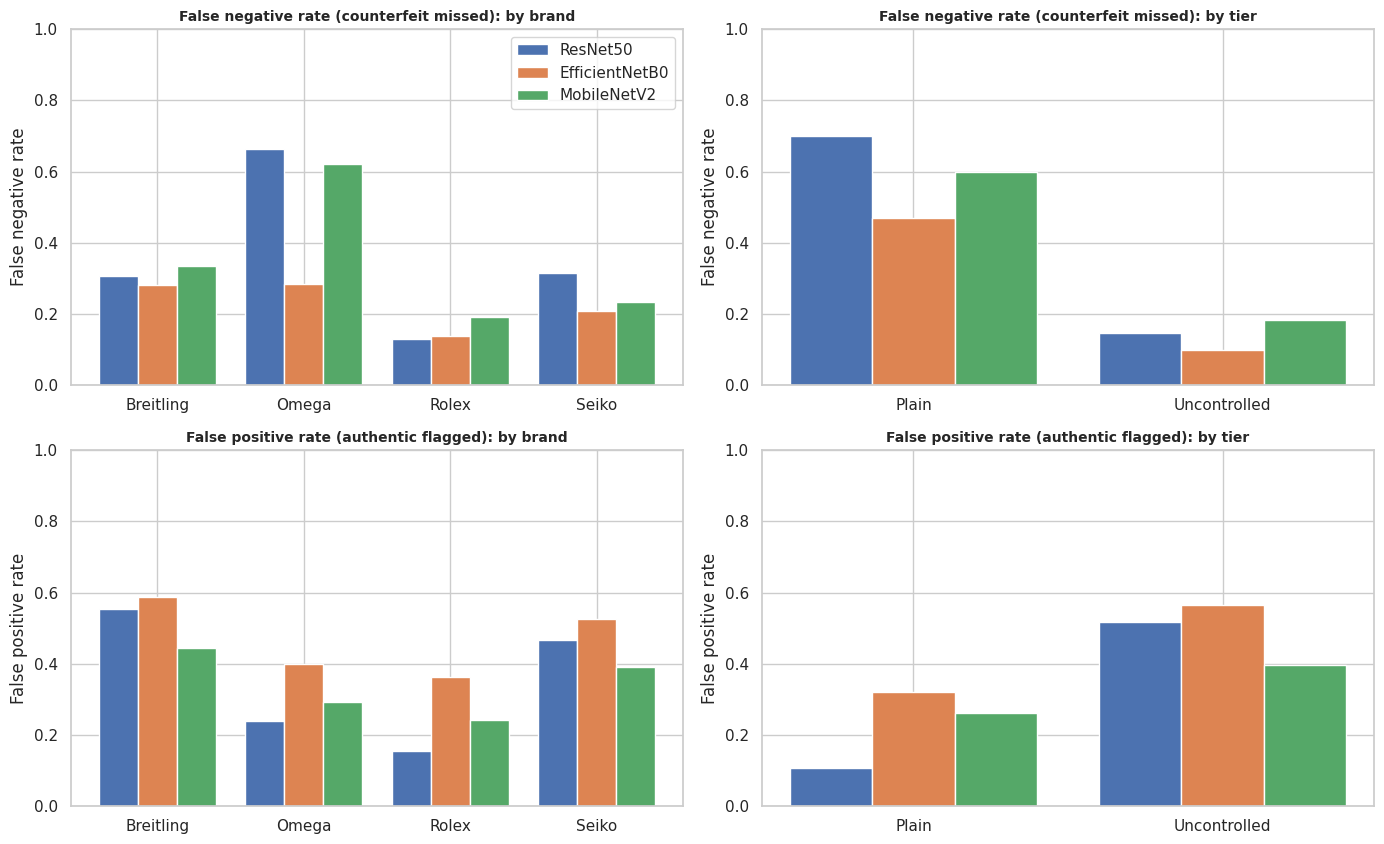

view,external test (final model),external test (majority of 15 models),pooled out-of-fold (majority of seeds)
category,,,
missed by none,86,92,210
missed only by ResNet50,26,14,38
missed only by EfficientNetB0,11,13,62
missed only by MobileNetV2,7,8,16
missed by exactly 2,22,25,113
missed by all 3,28,28,116



Do errors cluster in a few sellers? (share of each model's errors from the 3 sellers with most errors, against those sellers' share of images)


,view,arch,n_sellers,n_sellers_with_errors,total_errors,top3_share_of_errors,top10pct_share_of_errors,top3_share_of_images
0,pooled out-of-fold (majority of seeds),resnet50,52,40,217,0.323,0.488,0.195
1,pooled out-of-fold (majority of seeds),efficientnet_b0,52,40,250,0.268,0.400,0.195
2,pooled out-of-fold (majority of seeds),mobilenet_v2,52,40,223,0.305,0.466,0.195
3,external test (majority of 15 models),resnet50,35,26,57,0.368,0.421,0.283
4,external test (majority of 15 models),efficientnet_b0,35,28,58,0.293,0.362,0.283
5,external test (majority of 15 models),mobilenet_v2,35,29,54,0.370,0.426,0.283
6,external test (final model),resnet50,35,27,69,0.333,0.406,0.283
7,external test (final model),efficientnet_b0,35,25,53,0.302,0.377,0.283
8,external test (final model),mobilenet_v2,35,28,50,0.380,0.420,0.283


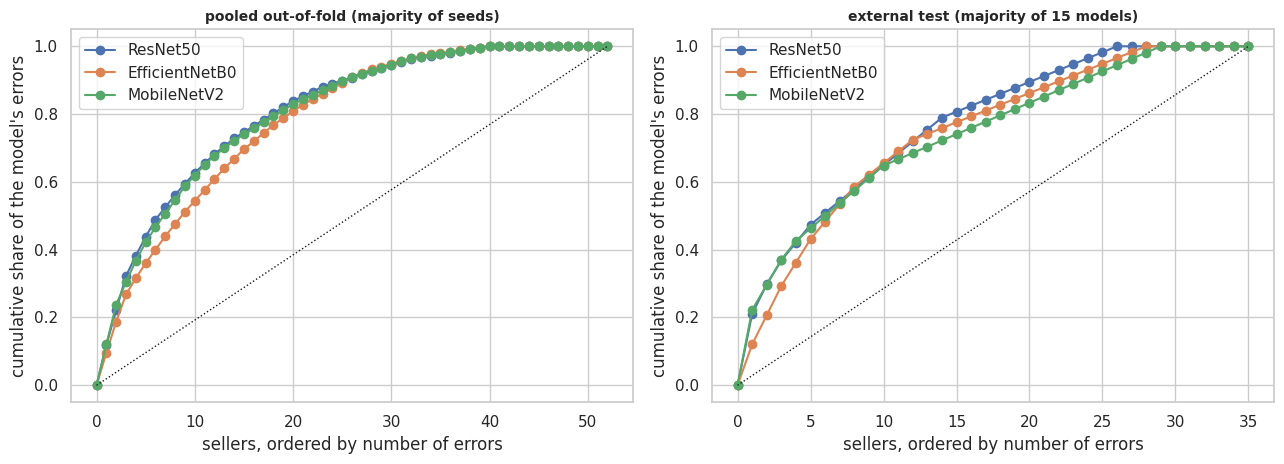


Images missed by every model: 28 on the test set, 116 in the pool


,rank,image_id,label,n_missed,missed_by,brand,tier,source,seller,mean_wrongness
178,1,test/counterfeit/CF-SEI-0352.jpg,1,3,"ResNet50, EfficientNetB0, MobileNetV2",Seiko,Plain,Paterson Jewellers,CF-0022,0.710
129,2,test/counterfeit/CF-OME-0156.webp,1,3,"ResNet50, EfficientNetB0, MobileNetV2",Omega,Plain,ORFactory,CF-0019,0.702
176,3,test/counterfeit/CF-SEI-0349.jpg,1,3,"ResNet50, EfficientNetB0, MobileNetV2",Seiko,Plain,Paterson Jewellers,CF-0022,0.693
128,4,test/counterfeit/CF-OME-0155.jpg,1,3,"ResNet50, EfficientNetB0, MobileNetV2",Omega,Plain,ORFactory,CF-0019,0.692
127,5,test/counterfeit/CF-OME-0154.jpg,1,3,"ResNet50, EfficientNetB0, MobileNetV2",Omega,Plain,ORFactory,CF-0019,0.662
112,6,test/counterfeit/CF-BRE-0423.jpg,1,3,"ResNet50, EfficientNetB0, MobileNetV2",Breitling,Plain,LuxuryWatch,CF-0012,0.650
131,7,test/counterfeit/CF-OME-0158.webp,1,3,"ResNet50, EfficientNetB0, MobileNetV2",Omega,Plain,ORFactory,CF-0019,0.640
120,8,test/counterfeit/CF-BRE-0457.jpg,1,3,"ResNet50, EfficientNetB0, MobileNetV2",Breitling,Plain,ORFactory,CF-0019,0.622
111,9,test/counterfeit/CF-BRE-0422.jpg,1,3,"ResNet50, EfficientNetB0, MobileNetV2",Breitling,Plain,LuxuryWatch,CF-0012,0.619
17,10,test/authentic/AU-BRE-0393.jpg,0,3,"ResNet50, EfficientNetB0, MobileNetV2",Breitling,Uncontrolled,eBay Authenticity Guarantee,AU-0054,0.613


In [10]:
# ==============================================================================
# SECTION 4.5.3: ERROR PATTERNS
# ==============================================================================
# CHAPTER 3: Evaluation (error analysis by brand, tier, source, label tier and seller)
VIEW = {"oof": "pooled out-of-fold (majority of seeds)", "test": "external test (majority of 15 models)", "final": "external test (final model)"}
dims = [d for d in ["brand", "tier", "source", "label_tier_num"] if d in W["oof"].columns]
rows = []
for k in W:
    for dim in dims:
        for lvl, g in W[k].dropna(subset=[dim]).groupby(dim):
            y = g.label.values; pos, neg = int((y == 1).sum()), int((y == 0).sum())
            for a in ARCHS:
                pr = g[f"pred_{a}"].values
                rows.append(dict(dimension="label_tier" if dim == "label_tier_num" else dim, group=lvl, evaluated_on=SET_NAME[k], arch=a, n_images=g.image_id.nunique(), n_counterfeit_images=g[g.label == 1].image_id.nunique(),
                                 n_authentic_images=g[g.label == 0].image_id.nunique(), fnr=((pr == 0) & (y == 1)).sum() / pos if pos else np.nan, fpr=((pr == 1) & (y == 0)).sum() / neg if neg else np.nan))
ER = pd.DataFrame(rows); savetab(ER.round(4), "t4_5_3_error_rates.csv", "4.5.3", "False negative and false positive rates by brand, tier, source and label tier, three models")
for dim in ER.dimension.unique():
    t = ER[(ER.dimension == dim) & (ER.evaluated_on == SET_NAME["test"])].pivot_table(index=["group", "n_images"], columns="arch", values=["fnr", "fpr"])
    t = t.reindex(columns=pd.MultiIndex.from_product([["fnr", "fpr"], ARCHS])); t.columns = [f"{m.upper()} {dn(a)}" for m, a in t.columns]; print(f"\nExternal test (15 models stacked): error rates by {dim}"); display(t.round(3))
fig, axes = plt.subplots(2, 2, figsize=(14, 8.6))
for c_, dim in enumerate([d for d in ["brand", "tier"] if d in ER.dimension.unique()]):
    for r_, (m, nm) in enumerate([("fnr", "False negative rate (counterfeit missed)"), ("fpr", "False positive rate (authentic flagged)")]):
        s = ER[(ER.dimension == dim) & (ER.evaluated_on == SET_NAME["test"])]; lv = sorted(s.group.unique()); w = 0.8 / len(ARCHS); ax = axes[r_, c_]
        for i, a in enumerate(ARCHS): ax.bar(np.arange(len(lv)) + (i - (len(ARCHS) - 1) / 2) * w, s[s.arch == a].set_index("group").reindex(lv)[m], w, color=col(a), label=dn(a))
        ax.set_xticks(range(len(lv))); ax.set_xticklabels(lv); ax.set_ylim(0, 1); ax.set_ylabel(nm.split(" (")[0]); ax.set_title(f"{nm}: by {dim}", fontsize=10, fontweight="bold")
axes[0, 0].legend(); savefig("f4_5_3_error_rates.png", "4.5.3", "False negative and false positive rates by brand and tier on the external test set")

# ---- per-image votes, missed images ---------------------------------------------------------------------------------------
def per_image(Wk):
    g = Wk.groupby("image_id"); out = pd.DataFrame({"label": g["label"].first()})
    for c in ["brand", "tier", "source", "seller", "group_id", "label_tier_num"]:
        if c in Wk.columns: out[c] = g[c].first()
    for a in ARCHS: out[f"prob_{a}"] = g[f"prob_{a}"].mean(); out[f"vote_{a}"] = (g[f"pred_{a}"].mean() > 0.5).astype(int)
    out["n_missed"] = sum((out[f"vote_{a}"] != out["label"]).astype(int) for a in ARCHS); out["missed_by"] = out.apply(lambda r: ", ".join(dn(a) for a in ARCHS if r[f"vote_{a}"] != r["label"]), axis=1)
    out["mean_wrongness"] = np.mean([np.abs(out[f"prob_{a}"] - out["label"]) for a in ARCHS], axis=0)
    return out.reset_index()
PI = {k: per_image(W[k]) for k in W}
nA = len(ARCHS); rows = []
for k, d in PI.items():
    n = len(d)
    rows.append(dict(view=VIEW[k], category="missed by none", n_images=int((d.n_missed == 0).sum()), share=(d.n_missed == 0).mean()))
    for a in ARCHS: rows.append(dict(view=VIEW[k], category=f"missed only by {dn(a)}", n_images=int(((d.n_missed == 1) & (d[f"vote_{a}"] != d.label)).sum()), share=((d.n_missed == 1) & (d[f"vote_{a}"] != d.label)).mean()))
    for j in range(2, nA): rows.append(dict(view=VIEW[k], category=f"missed by exactly {j}", n_images=int((d.n_missed == j).sum()), share=(d.n_missed == j).mean()))
    rows.append(dict(view=VIEW[k], category=f"missed by all {nA}", n_images=int((d.n_missed == nA).sum()), share=(d.n_missed == nA).mean()))
MC = pd.DataFrame(rows); savetab(MC.round(4), "t4_5_3_missed_counts.csv", "4.5.3", "Images missed by none, by only one, by two and by all three architectures"); display(MC.pivot(index="category", columns="view", values="n_images").reindex(MC.category.unique()))
keep = ["view", "image_id", "label", "n_missed", "missed_by", "brand", "tier", "source", "seller", "label_tier_num"] + [f"prob_{a}" for a in ARCHS]
MI = pd.concat([PI[k].assign(view=VIEW[k]) for k in PI]); MI = MI[MI.n_missed > 0].sort_values(["view", "n_missed", "mean_wrongness"], ascending=[True, False, False])
savetab(MI[[c for c in keep if c in MI.columns]].round(4), "t4_5_3_missed_images.csv", "4.5.3", "Every image missed by at least one model, with brand, tier, source, seller and probabilities")

# ---- sellers ---------------------------------------------------------------------------------------------------------------
srows, crows = [], []
for k, d in PI.items():
    if "seller" not in d.columns: continue
    g = d.groupby("seller")
    s = pd.DataFrame({"n_images": g.size()}); 
    for a in ARCHS: s[f"missed_{a}"] = g.apply(lambda x, a=a: int((x[f"vote_{a}"] != x["label"]).sum())); s[f"rate_{a}"] = s[f"missed_{a}"] / s["n_images"]
    s["missed_by_all"] = g.apply(lambda x: int((x.n_missed == nA).sum())); s = s.reset_index().assign(view=VIEW[k]).sort_values("n_images", ascending=False); srows.append(s)
    for a in ARCHS:
        e = s[f"missed_{a}"].sort_values(ascending=False).values; tot = e.sum()
        crows.append(dict(view=VIEW[k], arch=a, n_sellers=len(s), n_sellers_with_errors=int((e > 0).sum()), total_errors=int(tot), top3_share_of_errors=e[:3].sum() / tot if tot else np.nan,
                          top10pct_share_of_errors=e[:max(1, int(np.ceil(0.1 * len(s))))].sum() / tot if tot else np.nan, top3_share_of_images=s.n_images.sort_values(ascending=False).values[:3].sum() / s.n_images.sum()))
if srows:
    SS = pd.concat(srows, ignore_index=True); CO = pd.DataFrame(crows)
    savetab(SS.round(4), "t4_5_3_seller_summary.csv", "4.5.3", "Per-seller images and errors for each architecture"); savetab(CO.round(4), "t4_5_3_seller_concentration.csv", "4.5.3", "How concentrated the errors are in a few sellers")
    print("\nDo errors cluster in a few sellers? (share of each model's errors from the 3 sellers with most errors, against those sellers' share of images)"); display(CO.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, k in zip(axes, ["oof", "test"]):
        s = SS[SS.view == VIEW[k]]
        for a in ARCHS:
            e = s[f"missed_{a}"].sort_values(ascending=False).values; ax.plot(np.arange(0, len(e) + 1), np.r_[0, np.cumsum(e) / max(e.sum(), 1)], marker="o", color=col(a), label=dn(a))
        ax.plot([0, len(s)], [0, 1], "k:", lw=1); ax.set_xlabel("sellers, ordered by number of errors"); ax.set_ylabel("cumulative share of the model's errors"); ax.set_title(VIEW[k], fontsize=10, fontweight="bold"); ax.legend()
    savefig("f4_5_3_seller_error_concentration.png", "4.5.3", "Cumulative share of errors by seller (dotted line = errors spread evenly over sellers)")
else: print("No seller column in the predictions, so the seller summary is skipped.")

# ---- hardest images ------------------------------------------------------------------------------------------------------
hard = []
for k in ["test", "oof"]:
    d = PI[k].sort_values(["n_missed", "mean_wrongness"], ascending=False).head(20).assign(view=VIEW[k]); d.insert(1, "rank", range(1, len(d) + 1)); hard.append(d)
HARD = pd.concat(hard); HCOLS = ["view", "rank"] + [c for c in keep if c != "view" and c in HARD.columns] + ["mean_wrongness"]
savetab(HARD[HCOLS].round(4), "t4_5_3_hardest_images.csv", "4.5.3", "Twenty hardest images per set (most models wrong, then most confidently wrong), for the Grad-CAM discussion")
print(f"\nImages missed by every model: {int((PI['test'].n_missed == nA).sum())} on the test set, {int((PI['oof'].n_missed == nA).sum())} in the pool"); display(HARD[HARD.view == VIEW["test"]].head(10)[["rank", "image_id", "label", "n_missed", "missed_by", "brand", "tier", "source", "seller", "mean_wrongness"]].round(3))

## 4.6 Complexity
Parameters, MACs and model size do not depend on the hardware. Latency, memory and training time do, so they are only comparable when the hardware check in Section 0 passes. The per-layer table lists, for every convolution and linear layer, the terms of the chapter's time formula (H × W × K × F² × C multiply-accumulates) and space formula (K × F² × C weights).

,ResNet50,EfficientNetB0,MobileNetV2
total_params_M,23.5101,4.0088,2.2252
phase1_trainable_params_M,0.002,0.0013,0.0013
phase2_trainable_params_M,4.4646,1.1307,0.8874
flops_M_macs,8341.0964,784.1133,611.2141
conv_linear_macs_M,8341.0964,784.1133,611.2141
model_size_MB,89.989,15.5816,8.7247
inference_ms_per_image,8.4312,7.985,5.1782
inference_device,cuda,cuda,cuda
inference_ms_per_image_cpu,153.3076,42.8733,36.9003
peak_vram_inference_MB,328.8716,86.521,65.8701


arch,resnet50,efficientnet_b0,mobilenet_v2
n_layers,54,82,53
macs_M,8341.096,784.113,611.214
weights_M,23.457,3.967,2.191
heaviest_layer,conv1,features.8.0,features.18.0
heaviest_layer_share_of_macs,0.029,0.052,0.067
macs_share_1x1 conv or linear,0.519,0.882,0.895
weights_share_1x1 conv or linear,0.517,0.954,0.97
macs_share_k x k conv,0.481,0.028,0.036
weights_share_k x k conv,0.483,0.0,0.0
macs_share_depthwise or grouped conv,NaN,0.09,0.069


arch,resnet50,efficientnet_b0,mobilenet_v2
min_per_epoch_all,0.063,0.056,0.053
min_per_epoch_phase2,0.063,0.056,0.053
mean_epochs_trained,28.200,29.533,30.000
mean_best_epoch,25.267,25.933,27.800
mean_min_per_run,1.785,1.679,1.598
total_min_15_runs,26.779,25.188,23.965
final_model_min,2.003,1.638,1.694
total_min_all,28.783,26.826,25.659


arch,resnet50,efficientnet_b0,mobilenet_v2
test_auc,0.7187,0.7655,0.7600
test_auc_sd,0.0161,0.0278,0.0174
cv_auc,0.6740,0.5986,0.6475
cv_auc_sd,0.0800,0.1142,0.0795
final_test_auc,0.7182,0.8225,0.7982
total_params_M,23.5101,4.0088,2.2252
flops_M_macs,8341.0964,784.1133,611.2141
inference_ms_per_image,8.4312,7.9850,5.1782
model_size_MB,89.9890,15.5816,8.7247


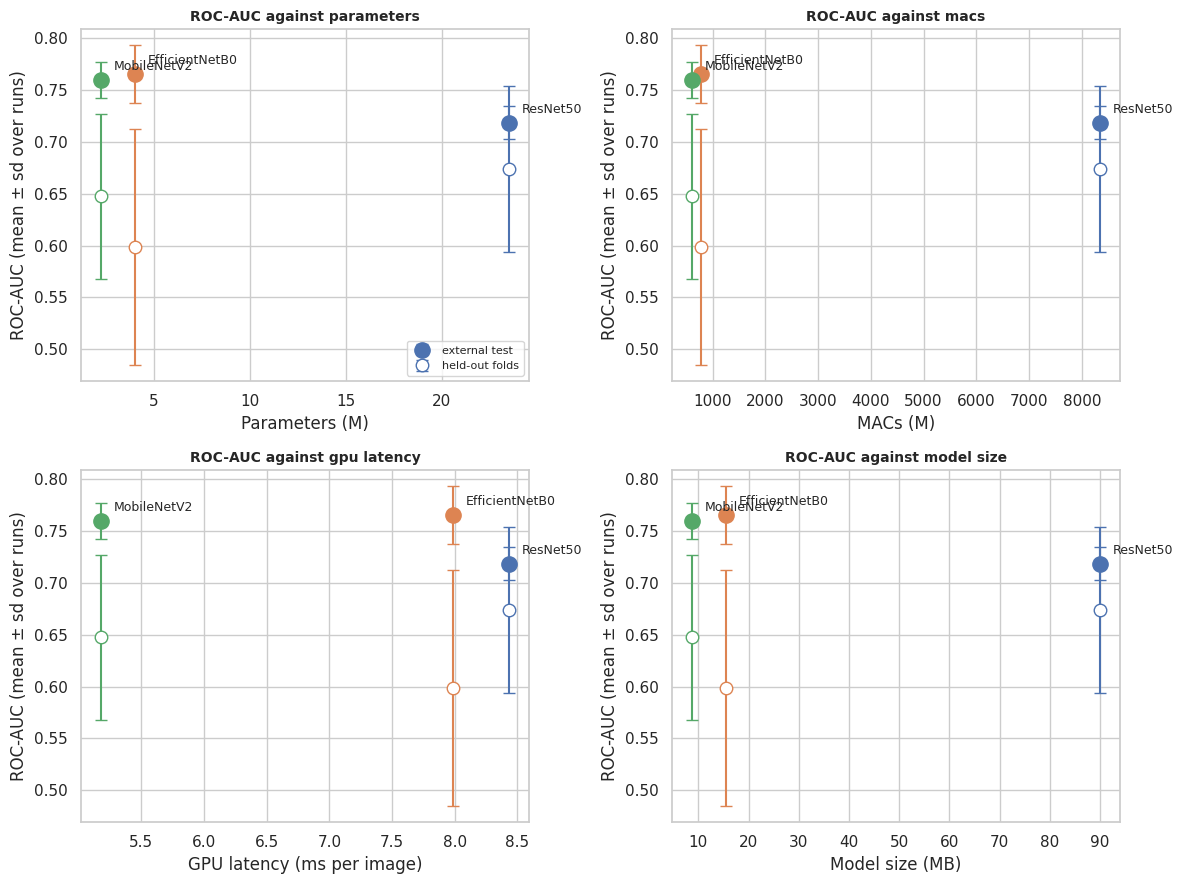

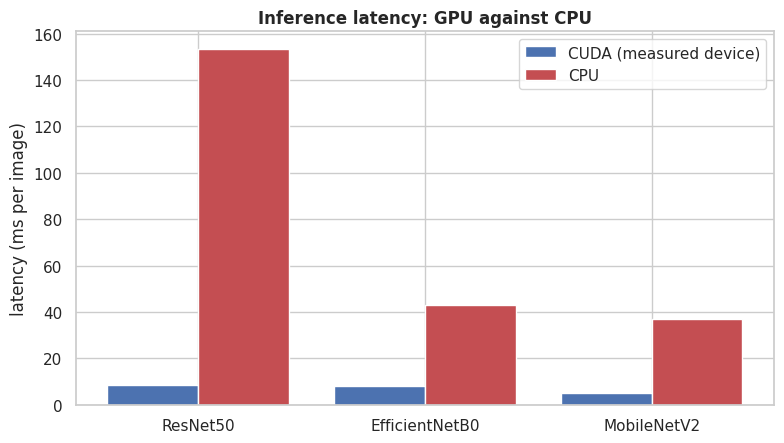

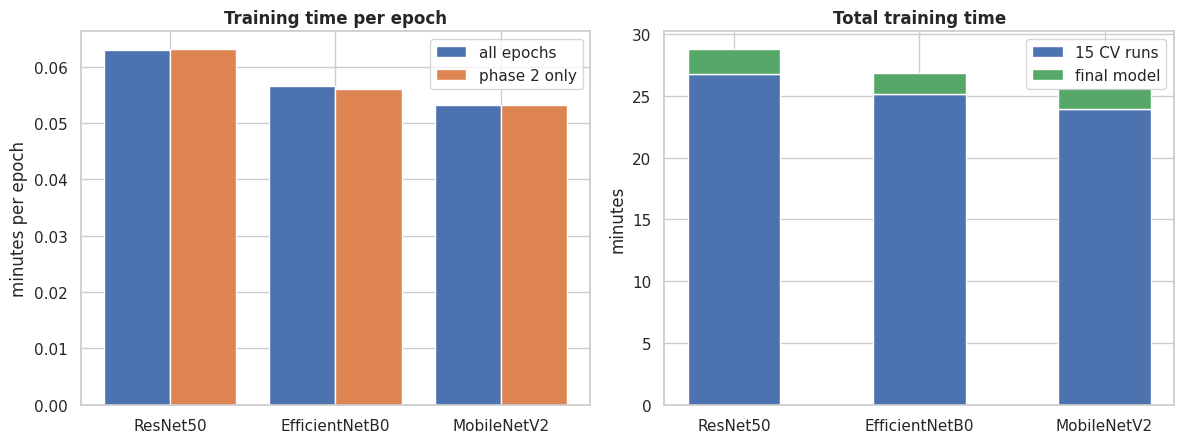

In [11]:
# ==============================================================================
# SECTION 4.6: COMBINED TABLE 3, PER-LAYER TERMS, ACCURACY-EFFICIENCY PLOTS, TRAINING TIME
# ==============================================================================
# CHAPTER 3: Time and Space Complexity Analysis (Table 3, RQ2)
if not HAVE_CX:
    print("[!] complexity_<arch>.csv is missing for at least one model, so Section 4.6 is skipped.")
else:
    cx = pd.concat([CX[a].assign(arch=a) for a in ARCHS], ignore_index=True)
    want = ["arch", "total_params_M", "phase1_trainable_params_M", "phase2_trainable_params_M", "flops_M_macs", "conv_linear_macs_M", "model_size_MB", "inference_ms_per_image", "inference_device", "inference_ms_per_image_cpu",
            "peak_vram_inference_MB", "peak_vram_training_MB", "train_min_per_epoch_all", "train_min_per_epoch_phase2", "train_min_per_run_cv_mean", "train_min_final_model", "hardware"]
    t3 = cx.reindex(columns=[c for c in want if c in cx.columns]); savetab(t3.round(4), "t4_6_table3_complexity.csv", "4.6", "Combined Table 3: parameters, MACs, latency (GPU and CPU), model size, memory, training time per epoch")
    show = t3.set_index("arch").T; show.columns = [dn(a) for a in show.columns]; display(show)

    if all(CXL[a] is not None for a in ARCHS):
        L = pd.concat([CXL[a].assign(arch=a) for a in ARCHS], ignore_index=True); savetab(L, "t4_6_layer_terms.csv", "4.6", "Per-layer time (MACs) and space (weights) terms for all three architectures")
        try:
            L["kernel_class"] = np.where(L.groups > 1, "depthwise or grouped conv", np.where(L.F_kernel.astype(str) == "1x1", "1x1 conv or linear", "k x k conv"))
            rows = []
            for a in ARCHS:
                g = L[L.arch == a]; top = g.loc[g.macs.idxmax()]
                row = dict(arch=a, n_layers=len(g), macs_M=g.macs.sum() / 1e6, weights_M=g.weights.sum() / 1e6, heaviest_layer=top.layer, heaviest_layer_share_of_macs=top.macs / g.macs.sum())
                for cl, h in g.groupby("kernel_class"): row[f"macs_share_{cl}"] = h.macs.sum() / g.macs.sum(); row[f"weights_share_{cl}"] = h.weights.sum() / g.weights.sum()
                rows.append(row)
            LS = pd.DataFrame(rows); savetab(LS.round(4), "t4_6_layer_summary.csv", "4.6", "Per-architecture totals of the per-layer terms and their split by kernel type"); display(LS.round(3).set_index("arch").T)
        except Exception as e: print("[!] Layer summary skipped:", type(e).__name__, e)
    else: print("[!] complexity_layers_<arch>.csv is missing for at least one model, so the per-layer terms are skipped.")

    rows = []
    for a in ARCHS:
        r, c, f = RUNS[a], CX[a].iloc[0], FINROW[a].iloc[0]
        rows.append(dict(arch=a, min_per_epoch_all=c.get("train_min_per_epoch_all", r.mean_epoch_sec.mean() / 60), min_per_epoch_phase2=c.get("train_min_per_epoch_phase2", r.phase2_epoch_sec.mean() / 60), mean_epochs_trained=r.epochs_trained.mean(),
                         mean_best_epoch=r.best_epoch.mean(), mean_min_per_run=r.train_minutes.mean(), total_min_15_runs=r.train_minutes.sum(), final_model_min=f.get("train_minutes", np.nan)))
    TT = pd.DataFrame(rows); TT["total_min_all"] = TT.total_min_15_runs + TT.final_model_min.fillna(0); savetab(TT.round(3), "t4_6_training_time.csv", "4.6", "Training time per epoch and in total per architecture"); display(TT.round(3).set_index("arch").T)

    perf = pd.DataFrame([dict(arch=a, test_auc=RUNS[a].test_roc_auc.mean(), test_auc_sd=RUNS[a].test_roc_auc.std(ddof=1), cv_auc=RUNS[a].heldout_roc_auc.mean(), cv_auc_sd=RUNS[a].heldout_roc_auc.std(ddof=1),
                          final_test_auc=ci("final", a, "roc_auc")[0]) for a in ARCHS]).merge(cx[["arch"] + [c for c in ["total_params_M", "flops_M_macs", "inference_ms_per_image", "model_size_MB"] if c in cx.columns]], on="arch")
    savetab(perf.round(4), "t4_6_accuracy_efficiency.csv", "4.6", "ROC-AUC next to parameters, MACs, latency and model size"); display(perf.round(4).set_index("arch").T)
    xs = [(c, l) for c, l in [("total_params_M", "Parameters (M)"), ("flops_M_macs", "MACs (M)"), ("inference_ms_per_image", "GPU latency (ms per image)"), ("model_size_MB", "Model size (MB)")] if c in perf]
    fig, axes = plt.subplots(2, 2, figsize=(12, 9)); 
    for ax, (c, l) in zip(axes.ravel(), xs):
        for _, r in perf.iterrows():
            ax.errorbar(r[c], r.test_auc, yerr=r.test_auc_sd, fmt="o", color=col(r.arch), ms=11, capsize=4, label="external test" if r.arch == ARCHS[0] else None)
            ax.errorbar(r[c], r.cv_auc, yerr=r.cv_auc_sd, fmt="o", mfc="white", color=col(r.arch), ms=9, capsize=4, label="held-out folds" if r.arch == ARCHS[0] else None)
            ax.annotate(dn(r.arch), (r[c], r.test_auc), textcoords="offset points", xytext=(9, 7), fontsize=9)
        ax.set_xlabel(l); ax.set_ylabel("ROC-AUC (mean ± sd over runs)"); ax.set_title(f"ROC-AUC against {l.split(' (')[0].lower()}", fontweight="bold", fontsize=10)
    axes[0, 0].legend(fontsize=8, loc="lower right"); savefig("f4_6_accuracy_efficiency.png", "4.6", "ROC-AUC against parameters, MACs, GPU latency and model size (filled = test, hollow = held-out folds)")

    if "inference_ms_per_image_cpu" in cx.columns:
        dev = str(cx.inference_device.iloc[0]).upper() if "inference_device" in cx.columns else "GPU"; fig, ax = plt.subplots(figsize=(8, 4.6)); x = np.arange(len(ARCHS))
        ax.bar(x - 0.2, cx.set_index("arch").loc[ARCHS, "inference_ms_per_image"], 0.4, label=f"{dev} (measured device)", color="#4C72B0"); ax.bar(x + 0.2, cx.set_index("arch").loc[ARCHS, "inference_ms_per_image_cpu"], 0.4, label="CPU", color="#C44E52")
        if cx[["inference_ms_per_image", "inference_ms_per_image_cpu"]].max().max() / cx[["inference_ms_per_image", "inference_ms_per_image_cpu"]].min().min() > 30: ax.set_yscale("log")
        ax.set_xticks(x); ax.set_xticklabels([dn(a) for a in ARCHS]); ax.set_ylabel("latency (ms per image)"); ax.legend(); ax.set_title("Inference latency: GPU against CPU", fontweight="bold"); savefig("f4_6_latency_cpu_gpu.png", "4.6", "Inference latency on GPU and CPU per architecture")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6)); x = np.arange(len(ARCHS)); t_ = TT.set_index("arch").loc[ARCHS]
    axes[0].bar(x - 0.2, t_.min_per_epoch_all, 0.4, label="all epochs", color="#4C72B0"); axes[0].bar(x + 0.2, t_.min_per_epoch_phase2, 0.4, label="phase 2 only", color="#DD8452")
    axes[1].bar(x, t_.total_min_15_runs, 0.5, label="15 CV runs", color="#4C72B0"); axes[1].bar(x, t_.final_model_min.fillna(0), 0.5, bottom=t_.total_min_15_runs, label="final model", color="#55A868")
    for ax, tl, yl in [(axes[0], "Training time per epoch", "minutes per epoch"), (axes[1], "Total training time", "minutes")]:
        ax.set_xticks(x); ax.set_xticklabels([dn(a) for a in ARCHS]); ax.set_ylabel(yl); ax.set_title(tl, fontweight="bold"); ax.legend()
    savefig("f4_6_training_time.png", "4.6", "Training time per epoch and total training time per architecture")

### 4.6 Pareto frontier: quality against time and space
A model is Pareto-optimal when no other model is at least as good on both quality and the cost measure and strictly better on one. A dominated model is never the better choice, whatever weight is put on quality versus cost, so no weighting needs to be assumed.

The quality axis is set by `PARETO_EVAL` and `PARETO_QUALITY` in Section 0 (default is the mean external test ROC-AUC over the runs, with the standard deviation over the runs as the error bar). Time is GPU latency per image and space is model size. Both axes are drawn so that top-right is best. The step line connects the optimal points only and the shaded zone is dominated.

Dominance is read from the means, so the table also reports whether the dominating model's ROC-AUC advantage is significant in the paired bootstrap of Section 4.5. A dominated model whose gap is not significant is only dominated on paper.

In [12]:
# ==============================================================================
# SECTION 4.6 (Pareto 1): PARETO HELPERS
# ==============================================================================
# CHAPTER 3: Time and Space Complexity Analysis (Pareto frontier, RQ2)
def pareto_dominators(x, y, minimize_x=True, maximize_y=True):
    "For every point, the indices of the points that dominate it (at least as good on both objectives, strictly better on one)."
    x = np.asarray(x, float); y = np.asarray(y, float); out = []
    for i in range(len(x)):
        dom = []
        for j in range(len(x)):
            if i == j: continue
            x_ok = x[j] <= x[i] if minimize_x else x[j] >= x[i]
            y_ok = y[j] >= y[i] if maximize_y else y[j] <= y[i]
            strict = (x[j] < x[i] if minimize_x else x[j] > x[i]) or (y[j] > y[i] if maximize_y else y[j] < y[i])
            if x_ok and y_ok and strict: dom.append(j)
        out.append(dom)
    return out

def declutter_labels(ax, annotations, iterations=8, max_total_offset_pt=70):
    "Push apart annotation labels whose rendered boxes overlap, with a cap on how far each label may drift."
    fig = ax.figure; fig.canvas.draw(); renderer = fig.canvas.get_renderer(); px_to_pt = 72.0 / fig.dpi
    start = [np.array(a.xyann, dtype=float) for a in annotations]
    for _ in range(iterations):
        boxes = [a.get_window_extent(renderer=renderer) for a in annotations]; moved = False
        for i in range(len(annotations)):
            for j in range(i + 1, len(annotations)):
                bi, bj = boxes[i], boxes[j]
                if not bi.overlaps(bj): continue
                moved = True
                ci = np.array([(bi.x0 + bi.x1) / 2, (bi.y0 + bi.y1) / 2]); cj = np.array([(bj.x0 + bj.x1) / 2, (bj.y0 + bj.y1) / 2])
                delta = ci - cj
                if np.allclose(delta, 0): delta = np.array([0.0, 1.0])
                direction = delta / np.hypot(*delta)
                push = min(max(min(bi.x1, bj.x1) - max(bi.x0, bj.x0), min(bi.y1, bj.y1) - max(bi.y0, bj.y0)) / 2 + 3, 25)
                for k, sign in ((i, 1), (j, -1)):
                    new = np.array(annotations[k].xyann) + sign * direction * push * px_to_pt; drift = new - start[k]; mag = np.hypot(*drift)
                    if mag > max_total_offset_pt: new = start[k] + drift / mag * max_total_offset_pt
                    annotations[k].xyann = tuple(new)
        if not moved: break
        fig.canvas.draw(); renderer = fig.canvas.get_renderer()

def plot_pareto_tradeoff(df, ax, x_col, x_label, pareto_col, y_col, y_label, maximize_y=True, invert_x=True, yerr_col=None, title=None):
    "One quality measure (y) against one cost measure (x). Step frontier through the optimal points, shaded dominated zone, decluttered labels. x is inverted by default and y is inverted when lower is better, so top-right is always best."
    invert_y = not maximize_y
    err = df[yerr_col].fillna(0).to_numpy() if yerr_col else np.zeros(len(df))
    x_min, x_max = df[x_col].min(), df[x_col].max(); x_span = (x_max - x_min) or (abs(x_max) * 0.1 or 1.0)
    y_lo_v, y_hi_v = (df[y_col] - err).min(), (df[y_col] + err).max(); y_span = (y_hi_v - y_lo_v) or (abs(y_hi_v) * 0.1 or 1.0)
    y_floor, y_ceil = y_lo_v - y_span * 0.18, y_hi_v + y_span * 0.18; x_lo, x_hi = x_min - x_span * 0.28, x_max + x_span * 0.28
    fr = df[df[pareto_col]].sort_values(x_col); fx, fy = fr[x_col].to_numpy(), fr[y_col].to_numpy()
    ext_fx = np.concatenate(([x_lo], fx, [x_hi])); ext_fy = np.concatenate(([fy[0]], fy, [fy[-1]]))
    ax.step(ext_fx, ext_fy, where="post", linestyle="--", color="dimgray", linewidth=1.5, zorder=1, label="Pareto frontier")
    if maximize_y: ax.fill_between(ext_fx, y_floor, ext_fy, step="post", color="red", alpha=0.06, zorder=0, label="Dominated region")
    else: ax.fill_between(ext_fx, ext_fy, y_ceil, step="post", color="red", alpha=0.06, zorder=0, label="Dominated region")
    n = len(df); stagger = [0, 16, -16, 8, -8][:n] if n <= 5 else [0] * n; annotations = []
    for i, (_, row) in enumerate(df.iterrows()):
        opt = bool(row[pareto_col])
        if yerr_col: ax.errorbar(row[x_col], row[y_col], yerr=row[yerr_col], fmt="none", ecolor="gray", capsize=3, lw=1, zorder=2)
        ax.scatter(row[x_col], row[y_col], s=260 if opt else 160, marker="o" if opt else "X", color=col(row["arch"]), edgecolor="black", linewidth=1, zorder=3)
        annotations.append(ax.annotate(row["Model"], (row[x_col], row[y_col]), textcoords="offset points", xytext=(22, stagger[i]), fontsize=10, ha="left", va="center", zorder=4,
                                       arrowprops=dict(arrowstyle="-", color="gray", lw=0.6, shrinkA=6, shrinkB=2)))
    declutter_labels(ax, annotations)
    ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_floor, y_ceil)
    ax.set_xlabel(x_label + ("\n(← slower / larger        faster / smaller →)" if invert_x else ""), fontsize=12, linespacing=1.8); ax.set_ylabel(y_label, fontsize=11)
    ax.set_title(title or f"{y_label} vs {x_label}\n(● optimal, ✕ dominated, top-right = best)", fontsize=12)
    h, l = ax.get_legend_handles_labels(); ax.legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys(), loc="lower left", fontsize=8, framealpha=0.9)
    if invert_x: ax.invert_xaxis()
    if invert_y: ax.invert_yaxis()

def pareto_deltas(df, x_col, pareto_col, y_col):
    "Percent change in the cost measure and change in quality (in points, x100) relative to the cheapest Pareto-optimal model."
    ref = df[df[pareto_col]].sort_values(x_col).iloc[0]; out = df[["Model", x_col, y_col]].copy(); out["Reference model"] = ref["Model"]
    out["d_cost_pct"] = (out[x_col] - ref[x_col]) / ref[x_col] * 100; out["d_quality_points"] = (out[y_col] - ref[y_col]) * 100
    return out

,Model,ROC-AUC (external test),ROC-AUC sd over runs,Inference latency (ms/img),Model size (MB),1 - ROC-AUC,Throughput (img/s),Pareto (vs latency),Pareto (vs size)
0,ResNet50,0.7187,0.0161,8.4312,89.9890,0.2813,118.6071,False,False
1,EfficientNetB0,0.7655,0.0278,7.9850,15.5816,0.2345,125.2348,True,True
2,MobileNetV2,0.7600,0.0174,5.1782,8.7247,0.2400,193.1173,True,True


,trade_off,model,pareto_optimal,dominated_by,dominance_significant
0,latency,ResNet50,False,"EfficientNetB0, MobileNetV2",False
1,latency,EfficientNetB0,True,,NaN
2,latency,MobileNetV2,True,,NaN
3,model size,ResNet50,False,"EfficientNetB0, MobileNetV2",False
4,model size,EfficientNetB0,True,,NaN
5,model size,MobileNetV2,True,,NaN


Pareto-optimal on external test ROC-AUC vs inference latency: EfficientNetB0, MobileNetV2 | dominated: ResNet50
Pareto-optimal on external test ROC-AUC vs model size: EfficientNetB0, MobileNetV2 | dominated: ResNet50

[!] Dominated on the means, but the quality gap is not significant in the paired bootstrap: ResNet50 (latency); ResNet50 (model size) - report these as dominated on paper only.

Reference (fastest Pareto-optimal): MobileNetV2 | reference (smallest Pareto-optimal): MobileNetV2


,Model,Quality,Error,Latency,Throughput,Size,d_latency_vs_fastest_optimal_pct,d_roc_auc_vs_fastest_optimal_points_x100,d_size_vs_smallest_optimal_pct,d_roc_auc_vs_smallest_optimal_points_x100
0,ResNet50,0.719,0.281,8.431,118.607,89.989,62.821,-4.131,931.428,-4.131
1,EfficientNetB0,0.765,0.235,7.985,125.235,15.582,54.204,0.548,78.592,0.548
2,MobileNetV2,0.760,0.240,5.178,193.117,8.725,0.000,0.000,0.000,0.000


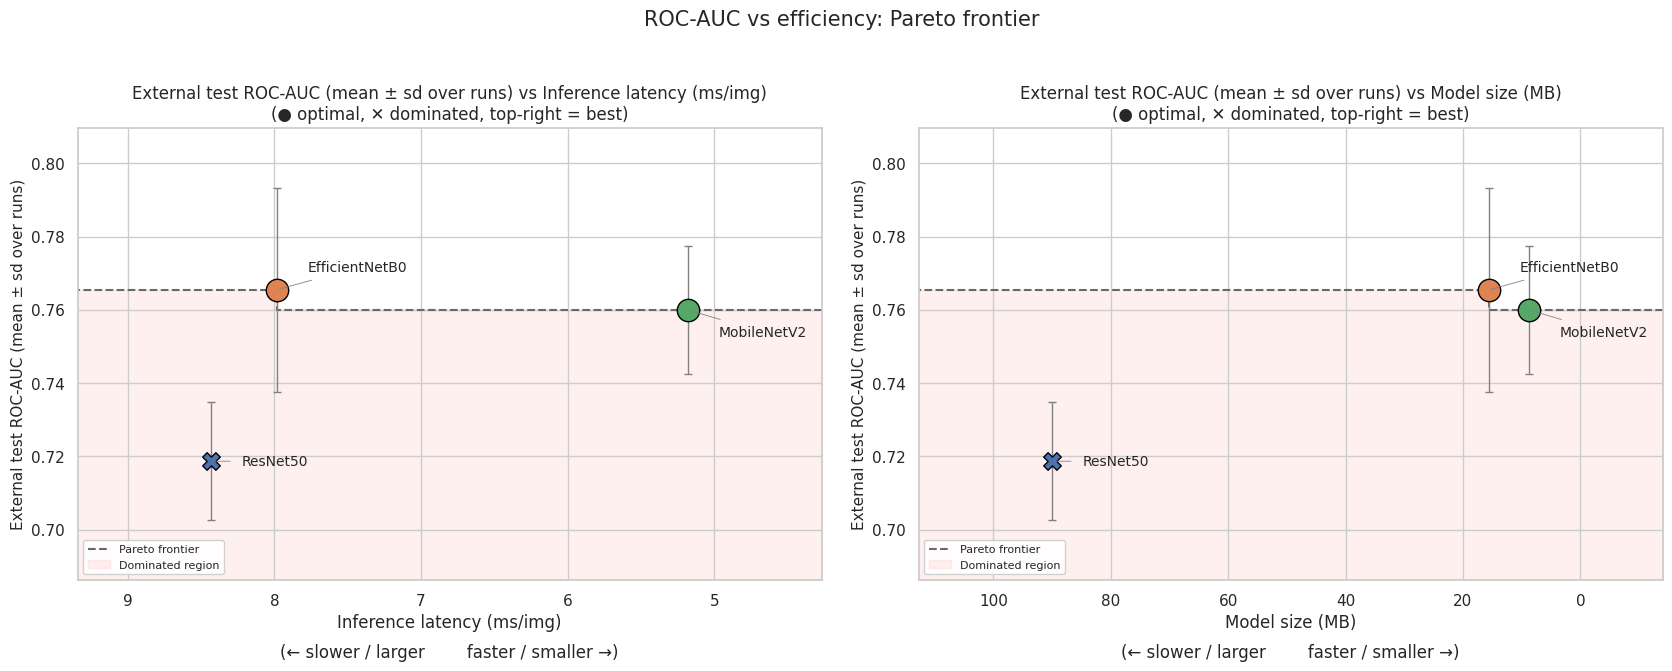

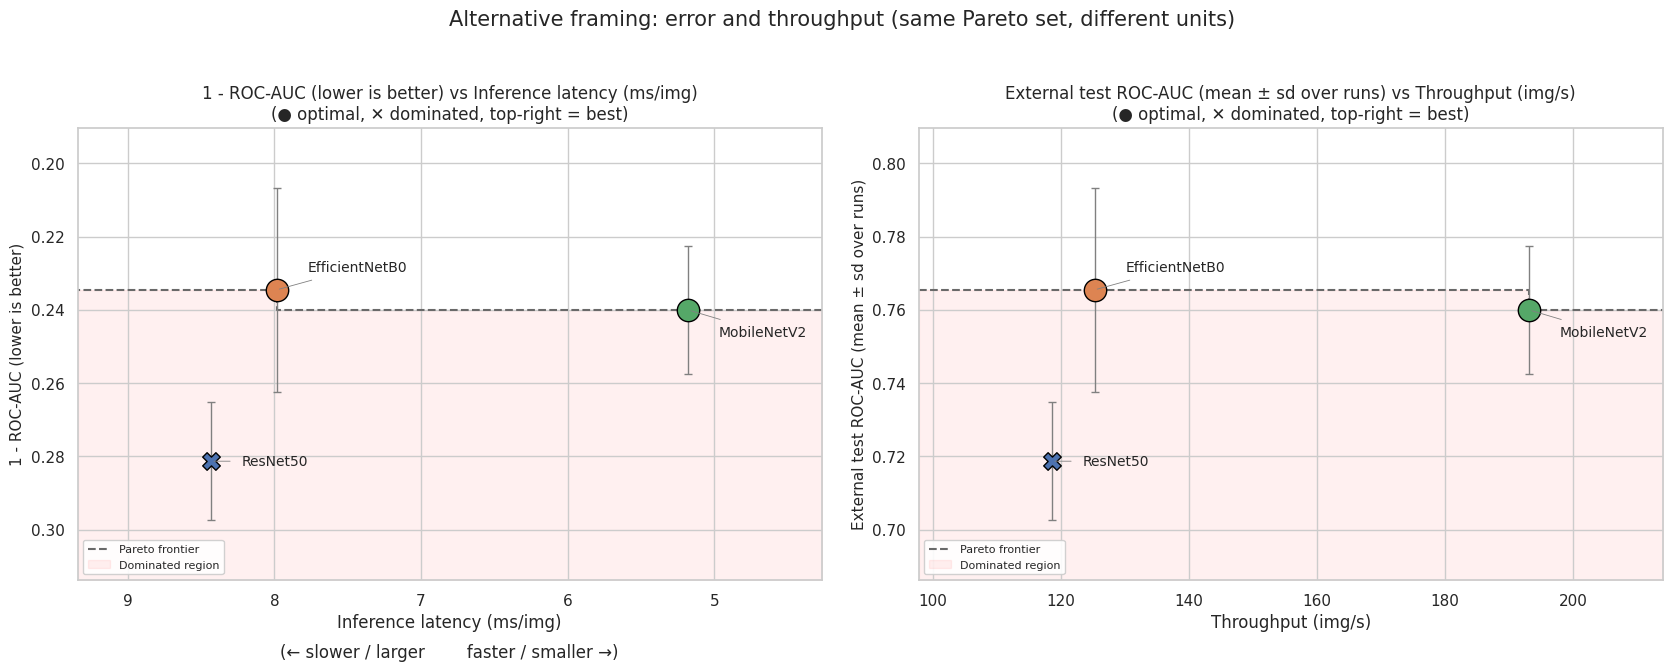

In [13]:
# ==============================================================================
# SECTION 4.6 (Pareto 2): PARETO ANALYSIS AND FIGURES
# ==============================================================================
# CHAPTER 3: Time and Space Complexity Analysis (accuracy or ROC-AUC against inference time and model size)
PARETO_SUMMARY = []
if not HAVE_CX or not all({"inference_ms_per_image", "model_size_MB"} <= set(CX[a].columns) for a in ARCHS):
    print("[!] complexity_<arch>.csv with inference_ms_per_image and model_size_MB is needed for every model, so the Pareto section is skipped.")
else:
    pre = {"test": "test_", "heldout": "heldout_"}[PARETO_EVAL]; QL = {"roc_auc": "ROC-AUC", "accuracy": "Accuracy"}[PARETO_QUALITY]; EL = {"test": "external test", "heldout": "cross-validation"}[PARETO_EVAL]
    rows = []
    for a in ARCHS:
        q = RUNS[a][pre + PARETO_QUALITY]
        rows.append(dict(arch=a, Model=dn(a), Quality=q.mean(), Quality_sd=q.std(ddof=1), Latency=float(CX[a].inference_ms_per_image.iloc[0]), Size=float(CX[a].model_size_MB.iloc[0])))
    T = pd.DataFrame(rows); T["Error"] = 1 - T.Quality; T["Throughput"] = 1000 / T.Latency
    dom_lat = pareto_dominators(T.Latency, T.Quality); dom_size = pareto_dominators(T.Size, T.Quality)
    T["Pareto_latency"] = [len(d) == 0 for d in dom_lat]; T["Pareto_size"] = [len(d) == 0 for d in dom_size]

    sup_set = SET_NAME["test" if PARETO_EVAL == "test" else "oof"]
    def supported(i, j):
        "Is the ROC-AUC advantage of model j over model i significant (Holm) in the paired bootstrap of Section 4.5?"
        a, b = ARCHS[i], ARCHS[j]
        r = PAIRS[(PAIRS.eval_set == sup_set) & (PAIRS.metric == "roc_auc") & (((PAIRS.model_a == a) & (PAIRS.model_b == b)) | ((PAIRS.model_a == b) & (PAIRS.model_b == a)))]
        if r.empty: return np.nan
        r = r.iloc[0]; adv_b = -r.diff_a_minus_b if r.model_a == a else r.diff_a_minus_b
        return bool(r.reliable and adv_b > 0)

    drows = []
    for trade, dom in [("latency", dom_lat), ("model size", dom_size)]:
        for i, d in enumerate(dom):
            sig = np.nan if (not d or PARETO_QUALITY != "roc_auc") else all(supported(i, j) is True for j in d)
            drows.append(dict(trade_off=trade, model=dn(ARCHS[i]), pareto_optimal=len(d) == 0, dominated_by=", ".join(dn(ARCHS[j]) for j in d), dominance_significant=sig))
    DOM = pd.DataFrame(drows)

    show = T.rename(columns={"Quality": f"{QL} ({EL})", "Quality_sd": f"{QL} sd over runs", "Latency": "Inference latency (ms/img)", "Size": "Model size (MB)", "Error": f"1 - {QL}",
                             "Throughput": "Throughput (img/s)", "Pareto_latency": "Pareto (vs latency)", "Pareto_size": "Pareto (vs size)"})
    savetab(show.round(4), "t4_6_pareto_tradeoff.csv", "4.6", "Pareto analysis: quality, latency, size and Pareto-optimal flags"); display(show.drop(columns="arch").round(4)); savetab(DOM, "t4_6_pareto_dominance.csv", "4.6", "Which model dominates which, and whether the quality gap is significant"); display(DOM)
    for trade, c in [("inference latency", "Pareto_latency"), ("model size", "Pareto_size")]:
        opt, dm = T.loc[T[c], "Model"].tolist(), T.loc[~T[c], "Model"].tolist()
        msg = f"Pareto-optimal on {EL} {QL} vs {trade}: {', '.join(opt)}" + (f" | dominated: {', '.join(dm)}" if dm else " | no model is dominated, every model is a real trade-off")
        print(msg); PARETO_SUMMARY.append(msg)
    weak = DOM[(~DOM.pareto_optimal) & (DOM.dominance_significant == False)]
    if len(weak): print("\n[!] Dominated on the means, but the quality gap is not significant in the paired bootstrap:", "; ".join(f"{r.model} ({r.trade_off})" for r in weak.itertuples()), "- report these as dominated on paper only.")

    dl = pareto_deltas(T, "Latency", "Pareto_latency", "Quality"); ds = pareto_deltas(T, "Size", "Pareto_size", "Quality")
    delta = T[["Model", "Quality", "Error", "Latency", "Throughput", "Size"]].copy()
    delta["d_latency_vs_fastest_optimal_pct"] = dl["d_cost_pct"]; delta[f"d_{PARETO_QUALITY}_vs_fastest_optimal_points_x100"] = dl["d_quality_points"]
    delta["d_size_vs_smallest_optimal_pct"] = ds["d_cost_pct"]; delta[f"d_{PARETO_QUALITY}_vs_smallest_optimal_points_x100"] = ds["d_quality_points"]
    print(f"\nReference (fastest Pareto-optimal): {dl['Reference model'].iloc[0]} | reference (smallest Pareto-optimal): {ds['Reference model'].iloc[0]}")
    savetab(delta.round(4), "t4_6_pareto_deltas.csv", "4.6", "Change in cost and quality relative to the cheapest Pareto-optimal model"); display(delta.round(3))

    if len(chk[chk.check.str.contains("hardware|device", case=False) & (chk.status == "WARN")]):
        print("\n[!] The latency measurements come from different hardware or devices, so the latency frontier is not valid. Model size is unaffected.")

    ql = f"{EL.capitalize()} {QL} (mean ± sd over runs)"
    fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
    plot_pareto_tradeoff(T, axes[0], "Latency", "Inference latency (ms/img)", "Pareto_latency", "Quality", ql, yerr_col="Quality_sd")
    plot_pareto_tradeoff(T, axes[1], "Size", "Model size (MB)", "Pareto_size", "Quality", ql, yerr_col="Quality_sd")
    fig.suptitle(f"{QL} vs efficiency: Pareto frontier", fontsize=15, y=1.03); savefig("f4_6_pareto_quality_vs_cost.png", "4.6", "Pareto frontier of quality against inference latency and model size")

    fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
    plot_pareto_tradeoff(T, axes[0], "Latency", "Inference latency (ms/img)", "Pareto_latency", "Error", f"1 - {QL} (lower is better)", maximize_y=False, yerr_col="Quality_sd")
    plot_pareto_tradeoff(T, axes[1], "Throughput", "Throughput (img/s)", "Pareto_latency", "Quality", ql, invert_x=False, yerr_col="Quality_sd")
    fig.suptitle("Alternative framing: error and throughput (same Pareto set, different units)", fontsize=15, y=1.03); savefig("f4_6_pareto_alt_framing.png", "4.6", "Pareto frontier, error and throughput framing")

## Supplementary: tiers, brand-website sensitivity and shortcut audit
Not part of the Chapter 4 outline above, kept because they bear on RQ4 and on the known data problems (brand-website images in the test set).

In [14]:
# ==============================================================================
# SECTION S: SUPPLEMENTARY BREAKDOWNS AND SHORTCUT AUDIT
# ==============================================================================
# CHAPTER 3: Evaluation (RQ4 matched background tiers), Shortcut Audit
def metric_row(g):
    return dict(zip(M5, five(g.label.values.astype(int), g.pred.values.astype(int), g.prob.values)))
EVSET = {"pooled out-of-fold": OOF, "external test (15 models)": TST}
rows = []
for dim in [d for d in ["tier", "brand", "source"] if d in OOF[ARCHS[0]].columns]:
    for es, src in EVSET.items():
        for a in ARCHS:
            for lvl, g in src[a].dropna(subset=[dim]).groupby(dim): rows.append(dict(dimension=dim, group=lvl, evaluated_on=es, arch=a, n_images=g.image_id.nunique(), **metric_row(g)))
BD = pd.DataFrame(rows); savetab(BD.round(4), "t4_s_breakdown_metrics.csv", "supplementary", "All metrics by tier, brand and source for each architecture")
print("ROC-AUC by background tier"); display(BD[BD.dimension == "tier"].pivot_table(index=["evaluated_on", "group", "n_images"], columns="arch", values="roc_auc")[ARCHS].rename(columns=dn).round(3))

rows = []
for es, src in EVSET.items():
    for a in ARCHS:
        g = src[a]
        if "brand_website" in g.columns and g.brand_website.any():
            for lab, gg in [("all images", g), ("without brand-website images", g[~g.brand_website])]: rows.append(dict(evaluated_on=es, arch=a, subset=lab, n_images=gg.image_id.nunique(), **metric_row(gg)))
if rows:
    bw = pd.DataFrame(rows); savetab(bw.round(4), "t4_s_brand_website_sensitivity.csv", "supplementary", "Results with and without brand-website images"); display(bw.pivot_table(index=["evaluated_on", "subset", "n_images"], columns="arch", values="roc_auc")[ARCHS].rename(columns=dn).round(3))
else: print("No brand-website images flagged, so the sensitivity check is skipped.")

have = [a for a in ARCHS if AUDIT[a] is not None]
if have:
    aud = pd.concat([AUDIT[a].assign(arch=a) for a in have], ignore_index=True); vals = [c for c in ["mean_accuracy", "mean_auc"] if c in aud]
    wide = aud.pivot_table(index="baseline", columns="arch", values=vals, sort=False); wide.columns = [f"{v}_{a}" for v, a in wide.columns]
    savetab(wide.round(4).reset_index(), "t4_s_shortcut_audit.csv", "supplementary", "Shortcut audit baselines from the three notebooks side by side"); display(wide.round(3))
    for v in vals:
        sp = aud.pivot_table(index="baseline", columns="arch", values=v).pipe(lambda d: d.max(axis=1) - d.min(axis=1))
        if (sp > 0.02).any(): print(f"[!] {v} differs by more than 0.02 between the notebooks for: {', '.join(sp[sp > 0.02].index)}")

ROC-AUC by background tier


arch                                             ResNet50  EfficientNetB0  \
evaluated_on              group        n_images                             
external test (15 models) Plain        68           0.665           0.711   
                          Uncontrolled 112          0.775           0.827   
pooled out-of-fold        Plain        217          0.669           0.517   
                          Uncontrolled 338          0.727           0.706   

arch                                             MobileNetV2  
evaluated_on              group        n_images               
external test (15 models) Plain        68              0.614  
                          Uncontrolled 112             0.854  
pooled out-of-fold        Plain        217             0.587  
                          Uncontrolled 338             0.714

arch                                                             ResNet50  \
evaluated_on              subset                       n_images             
external test (15 models) all images                   180          0.714   
                          without brand-website images 141          0.626   
pooled out-of-fold        all images                   555          0.700   
                          without brand-website images 439          0.668   

arch                                                             EfficientNetB0  \
evaluated_on              subset                       n_images                   
external test (15 models) all images                   180                0.763   
                          without brand-website images 141                0.705   
pooled out-of-fold        all images                   555                0.645   
                          without brand-website images 439                0.618   

arch                                                             MobileNetV2  
evaluated_on              subset                       n_images               
external test (15 models) all images                   180             0.758  
                          without brand-website images 141             0.727  
pooled out-of-fold        all images                   555             0.670  
                          without brand-website images 439             0.664

,mean_accuracy_resnet50,mean_accuracy_efficientnet_b0,mean_accuracy_mobilenet_v2,mean_auc_resnet50,mean_auc_efficientnet_b0,mean_auc_mobilenet_v2
baseline,,,,,,
B1 file size + re-encode ratio,0.688,0.688,0.688,0.837,0.837,0.837
"B2 resolution, blur, brightness, colour histogram, JPEG quality",0.810,0.810,0.810,0.885,0.885,0.885
B1p file size of the PROCESSED image (what the CNN sees),0.509,0.509,0.509,0.571,0.571,0.571
"B2p PROCESSED image: size, sharpness, brightness, contrast, white share, edges, colour histogram",0.607,0.607,0.607,0.666,0.666,0.666
B3 mask area + shape,0.586,0.586,0.586,0.576,0.576,0.576
B4 background tier alone (metadata),0.299,0.299,0.299,0.391,0.391,0.391
"B5 border-only CNN, raw images",0.684,0.684,0.684,0.774,0.774,0.774
"B5 border-only CNN, processed images",0.552,0.552,0.552,0.628,0.628,0.628


## Summary, index and zip
The sentences are generated from the tables, so they match the numbers. An architecture is called better only when the Holm-adjusted interval excludes zero.

In [15]:
# ==============================================================================
# SECTION 9: SUMMARY, CHAPTER 4 INDEX AND ZIP
# ==============================================================================
# CHAPTER 3: none (summary and packaging)
lines = []
for k in W:
    b = BOOT[(BOOT.set_key == k) & (BOOT.metric == "roc_auc")].set_index("arch").loc[ARCHS].sort_values("estimate", ascending=False)
    lines.append(f"{SET_NAME[k]}, ROC-AUC: " + "; ".join(f"{dn(a)} {r.estimate:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]" for a, r in b.iterrows()) + ".")
    for r in PAIRS[(PAIRS.set_key == k) & (PAIRS.metric == "roc_auc")].itertuples():
        lines.append(f"   {dn(r.model_a)} vs {dn(r.model_b)}: difference {r.diff_a_minus_b:+.3f}, Holm-adjusted interval [{r.adj_ci_low:+.3f}, {r.adj_ci_high:+.3f}], {r.verdict}.")
oth = PAIRS[(PAIRS.metric != "roc_auc") & PAIRS.reliable]
if len(oth):
    lines.append("Accuracy, F1 and recall, reliable differences only:")
    lines += [f"   {MLAB[r.metric]}, {r.eval_set}, {dn(r.model_a)} vs {dn(r.model_b)}: {r.verdict} (difference {r.diff_a_minus_b:+.3f})" for r in oth.itertuples()]
else: lines.append("Accuracy, F1 and recall: no reliable difference between any pair of architectures in any evaluation set.")
lines.append(f"McNemar: {int((MCN.verdict != 'no reliable difference').sum())} of {len(MCN)} comparisons show a difference after Holm correction.")
if RUN_NB_TTEST: lines.append(f"Nadeau-Bengio on the held-out AUCs: {int((NB.verdict != 'no reliable difference').sum())} of {len(NB)} comparisons show a difference after Holm correction.")
lines.append("Generalisation, ROC-AUC change from held-out folds to test (positive = lower on test): " + "; ".join(f"{dn(r.arch)} {r.drop_cv_minus_test:+.3f}" for r in TN[TN.metric == "roc_auc"].itertuples()) + ".")
for m_ in globals().get("PARETO_SUMMARY", []): lines.append(m_)
if n_warn: lines.append(f"{n_warn} integrity WARN row(s); see t4_0_integrity_checks.csv.")
summary = "\n".join(lines); print(summary); open(f"{TAB}/t4_key_findings.txt", "w").write(summary)
INDEX.append(dict(type="table", section="summary", file="tables/t4_key_findings.txt", description="Generated key findings"))

def sec_key(s): return "999" if not re.match(r"^[0-9]", s) else ".".join(f"{int(x):03d}" for x in s.split("."))
IDX = pd.DataFrame(INDEX); IDX["_k"] = IDX.section.map(sec_key); IDX = IDX.sort_values(["_k", "type", "file"]).drop(columns="_k").reset_index(drop=True)
IDX.to_csv(f"{OUT}/chapter4_index.csv", index=False); display(IDX)

zip_path = f"{WORK}/comparison_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(f"{OUT}/chapter4_index.csv", arcname="chapter4_index.csv")
    for sub in (FIG, TAB):
        for f in sorted(os.listdir(sub)): z.write(f"{sub}/{f}", arcname=f"{os.path.basename(sub)}/{f}")
print(f"[✓] {zip_path} ({os.path.getsize(zip_path) / 2**20:.1f} MB) | figures {len(glob.glob(f'{FIG}/*.png'))} | tables {len(glob.glob(f'{TAB}/*.csv'))} | index: {OUT}/chapter4_index.csv")

pooled out-of-fold (3 seeds stacked), ROC-AUC: ResNet50 0.700 [0.611, 0.790]; MobileNetV2 0.670 [0.592, 0.753]; EfficientNetB0 0.645 [0.557, 0.750].
   ResNet50 vs EfficientNetB0: difference +0.055, Holm-adjusted interval [-0.036, +0.122], no reliable difference.
   ResNet50 vs MobileNetV2: difference +0.031, Holm-adjusted interval [-0.016, +0.077], no reliable difference.
   EfficientNetB0 vs MobileNetV2: difference -0.025, Holm-adjusted interval [-0.074, +0.033], no reliable difference.
external test (15 models stacked), ROC-AUC: EfficientNetB0 0.763 [0.661, 0.883]; MobileNetV2 0.758 [0.643, 0.895]; ResNet50 0.714 [0.595, 0.841].
   ResNet50 vs EfficientNetB0: difference -0.049, Holm-adjusted interval [-0.144, +0.009], no reliable difference.
   ResNet50 vs MobileNetV2: difference -0.044, Holm-adjusted interval [-0.140, +0.011], no reliable difference.
   EfficientNetB0 vs MobileNetV2: difference +0.005, Holm-adjusted interval [-0.065, +0.047], no reliable difference.
external test (

,type,section,file,description
0,table,0,tables/t4_0_integrity_checks.csv,Inputs and integrity checks
1,figure,4.2.4,figures/f4_2_4_per_fold_auc.png,Per-fold held-out ROC-AUC of the three architectures
2,table,4.2.4,tables/t4_2_4_cv_comparison.csv,"Comparative CV summary, three architectures side by side (mean ± sd and bootstrap CI)"
3,table,4.2.4,tables/t4_2_4_cv_comparison_numeric.csv,"Comparative CV summary, numeric values"
4,table,4.2.4,tables/t4_2_4_per_fold_auc.csv,"Per-fold held-out ROC-AUC (mean, sd and every seed), unstable folds flagged"
5,figure,4.3,figures/f4_3_threshold_spread.png,Spread of the frozen threshold per architecture
6,table,4.3,tables/t4_3_fixed_thresholds.csv,"Accuracy, precision, recall and F1 at the frozen theta and at 0.3, 0.5, 0.7 for CV runs and final models"
7,table,4.3,tables/t4_3_thresholds.csv,"Frozen threshold and its spread over the 15 runs, and the final model threshold"
8,figure,4.4,figures/f4_4_confusion_matrices.png,"Confusion matrices on the external test set, three architectures side by side (counts, row percentages)"
9,figure,4.4,figures/f4_4_roc_curves.png,"ROC curves of the three architectures on shared axes, pooled out-of-fold and external test (AUC in legend)"


[✓] /kaggle/working/comparison_results.zip (1.7 MB) | figures 12 | tables 31 | index: /kaggle/working/comparison/chapter4_index.csv
